In [1]:

# ============================================================
# CELL 0 — SHARED DRIVE STRUCTURE & DEVELOPER ONBOARDING
# ProofLens Research Project
# ============================================================

import json
import hashlib

from pathlib import Path
from google.colab import drive

# ------------------------------------------------------------
# 1. Mount Google Drive
# ------------------------------------------------------------

drive.mount("/content/drive")

DRIVE_ROOT = Path("/content/drive/MyDrive/cifaker")
MODELS_ROOT = DRIVE_ROOT / "models"

RELEASE_ID = "genimage-120k-v1"
EXPECTED_PLAN_ID = "plan_5f4143bb761cac8c"

MODEL_NAMES = [
    "Resnet50",
    "MobileNetV3-Large",
    "DenseNet121",
    "ConvNeXt-Tiny",
]

SEEDS = [42, 123, 2026]

assert DRIVE_ROOT.is_dir(), (
    f"Shared dataset folder not found: {DRIVE_ROOT}"
)

# ------------------------------------------------------------
# 2. Validate the existing published dataset
# ------------------------------------------------------------

RELEASE_DIR = (
    DRIVE_ROOT / "releases" / RELEASE_ID
)

RELEASE_METADATA_PATH = (
    RELEASE_DIR / "release.json"
)

assert RELEASE_METADATA_PATH.is_file(), (
    "Published release metadata was not found."
)

release_metadata = json.loads(
    RELEASE_METADATA_PATH.read_text(
        encoding="utf-8"
    )
)

assert release_metadata["status"] == "PUBLISHED"

assert release_metadata["sampling_plan_id"] == (
    EXPECTED_PLAN_ID
)

assert release_metadata["total_images"] == 120000
assert release_metadata["shard_count"] == 19

assert release_metadata["split_counts"] == {
    "train": 80000,
    "dev": 10000,
    "seen_test": 10000,
    "unseen_test": 20000,
}

assert release_metadata["verification_checks"]
assert all(
    release_metadata["verification_checks"].values()
)

print("Published dataset validation: PASS")

# ------------------------------------------------------------
# 3. Prepare the shared model directory structure
# ------------------------------------------------------------

MODELS_ROOT.mkdir(
    parents=True,
    exist_ok=True,
)

created_directories = []
existing_directories = []


def ensure_directory(path):

    path = Path(path)

    if path.exists():

        assert path.is_dir(), (
            f"Expected a directory: {path}"
        )

        existing_directories.append(path)

    else:

        path.mkdir(
            parents=True,
            exist_ok=True,
        )

        created_directories.append(path)

    return path


# Prevent accidental duplicate model directories
# caused by inconsistent capitalization.
existing_names = {
    path.name.casefold(): path.name
    for path in MODELS_ROOT.iterdir()
}

for model_name in MODEL_NAMES:

    existing_name = existing_names.get(
        model_name.casefold()
    )

    assert (
        existing_name is None
        or existing_name == model_name
    ), (
        f"Conflicting model folder: {existing_name}. "
        "Resolve the naming conflict before continuing."
    )


for model_name in MODEL_NAMES:

    model_root = ensure_directory(
        MODELS_ROOT / model_name
    )

    model_release_root = ensure_directory(
        model_root / RELEASE_ID
    )

    baseline_root = ensure_directory(
        model_release_root / "baseline"
    )

    ensure_directory(
        model_release_root / "experiments"
    )

    ensure_directory(
        model_release_root / "analysis"
    )

    for seed in SEEDS:

        ensure_directory(
            baseline_root / f"seed_{seed}"
        )

    print(f"Model workspace ready: {model_name}")

# ------------------------------------------------------------
# 4. Developer and AI agent onboarding documentation
# ------------------------------------------------------------

README_CONTENT = r"""# ProofLens — Shared Research Workspace

## 1. Project Overview

ProofLens is an AI-generated image detection research project.

The project investigates binary image classification,
cross-generator generalization, model robustness,
computational efficiency, and the reliability of
AI-generated image detectors.

The research team evaluates four CNN architectures:

- ResNet50
- MobileNetV3-Large
- DenseNet121
- ConvNeXt-Tiny

Each developer is responsible for their assigned architecture.

Developers should maintain consistent experimental protocols
while keeping model-specific implementation and research
experiments independent.

## 2. Current Project Status

The Data Engineering Phase has been completed.

The official GenImage-120K v1 dataset has been materialized,
verified, published, and successfully tested using the
production dataset consumer.

Current phase:

Model Training and Research Experiments.

Do not rebuild the dataset unless a new dataset release
has been explicitly approved by the research team.

## 3. Authoritative Resources

GitHub repository:

https://github.com/sangoonthego/cifaker

Shared Google Drive:

https://drive.google.com/drive/folders/1IipfeWX_OVJS2KwaFL5wFlO-edxLoEGD

Verified data pipeline commit:

d3d313cdb1b46d951ff5ddc863ae501e194a5d3a

Original sampling commit:

d76c8fd6105bfef029bcb2b8dbead255bf03ff5c

The pinned data pipeline commit has been validated through
the production materialization and consumer smoke tests.

If a newer repository commit is required for training,
audit its compatibility before using it and record the
actual commit in the experiment configuration.

## 4. Official Dataset Release

| Property | Value |
|---|---|
| Release ID | genimage-120k-v1 |
| Publication status | PUBLISHED |
| Dataset type | Full GenImage-derived research subset |
| Frozen sampling plan | plan_5f4143bb761cac8c |
| Sampling seed | 20260401 |
| Total images | 120,000 |
| REAL images | 60,000 |
| FAKE images | 60,000 |
| TAR shards | 19 |
| Storage size | Approximately 24.40 GiB |
| REAL label | 0 |
| FAKE label | 1 |
| Manifest SHA-256 | __MANIFEST_SHA256__ |

This dataset is not CIFAKE or Tiny GenImage.

The dataset was derived from the pinned Hugging Face
GenImage Arrow mirror:

https://huggingface.co/datasets/nebula/GenImage-arrow

Source revision:

3f4b9f921a673be09a93b335ed728cea0c6ecf33

Developers must consume the published Google Drive release
instead of downloading or resampling the upstream dataset.

## 5. Experimental Dataset Splits

| Split | REAL | FAKE | Total | Purpose |
|---|---:|---:|---:|---|
| train | 40,000 | 40,000 | 80,000 | Parameter learning |
| dev | 5,000 | 5,000 | 10,000 | Model selection |
| seen_test | 5,000 | 5,000 | 10,000 | Seen-generator evaluation |
| unseen_test | 10,000 | 10,000 | 20,000 | Cross-generator evaluation |
| Total | 60,000 | 60,000 | 120,000 | |

The split assignments are frozen.

Do not:

- Create a new random train/test split.
- Move images between experimental splits.
- Remove images from the official release.
- Tune hyperparameters using test-set results.
- Train on seen_test or unseen_test.
- Perform data augmentation on validation images
  unless explicitly conducting a robustness experiment.
- Silently exclude failed or difficult samples.

Use the dev split for early stopping, checkpoint selection,
threshold selection, calibration fitting, and development.

Use the test splits for final evaluation after the relevant
experimental configurations and analysis rules are locked.

## 6. Generator Protocol

Seen generator groups:

- ADM (adm)
- BigGAN (biggan)
- GLIDE (glide)
- Stable Diffusion v1.4 (sdv4)
- Stable Diffusion v1.5 (sdv5)
- VQDM (vqdm)

Unseen generator groups:

- Midjourney (midjourney)
- Wukong (wukong)

The unseen generator groups are excluded from training
and development under the official dataset protocol.

The main research objective is not limited to detection
accuracy. Generalization to unseen generators is also
a critical evaluation dimension.

For generator groups containing only FAKE images, report
Fake Recall or False Negative Rate.

Metrics requiring both classes should only be calculated
when appropriate REAL and FAKE samples are available.

## 7. Google Drive Workspace

The shared directory structure is:

```text
cifaker/
├── README.md
├── releases/
│   └── genimage-120k-v1/
│       ├── release.json
│       ├── manifest.parquet
│       ├── checksums.json
│       ├── audit_summary.json
│       ├── plan.json
│       ├── state.json
│       └── ...
├── pipeline_metadata/
└── models/
    ├── Resnet50/
    ├── MobileNetV3-Large/
    ├── DenseNet121/
    └── ConvNeXt-Tiny/
```

Each model directory follows this structure:

```text
models/<model_name>/
└── genimage-120k-v1/
    ├── baseline/
    │   ├── seed_42/
    │   ├── seed_123/
    │   └── seed_2026/
    ├── experiments/
    └── analysis/
```

Model directory names are case-sensitive conventions.

Use the exact names listed above.

Do not create additional folders for the same architecture
using different capitalization or spelling.

## 8. Model Ownership and Protected Paths

Each developer should write artifacts only within their
assigned model directory.

For example, the ResNet50 developer owns:

```text
cifaker/models/Resnet50/
```

Protected shared paths:

```text
cifaker/releases/
cifaker/pipeline_metadata/
```

These paths contain published dataset artifacts and
data engineering provenance.

Treat them as read-only.

Do not modify or delete another developer's model artifacts.

Do not save model weights, training checkpoints, or temporary
experiment files inside the official dataset release.

## 9. Recommended Google Colab Workflow

Use Google Colab with a GPU runtime for CNN training.

Recommended notebook organization:

Cell 1:
Environment setup, Google Drive authentication,
repository synchronization, dependency installation,
and GPU validation.

Cell 2:
Experiment configuration, dataset loading,
runtime cache preparation, preprocessing, and DataLoader.

Cell 3:
Model initialization, loss function, optimizer,
scheduler, training engine, and checkpoint functions.

Cell 4:
Training execution, validation, early stopping,
and persistent checkpointing.

Cell 5:
Development evaluation, learning curves,
predictions, metrics, and artifact export.

Keep data engineering and model training independent.

Training notebooks must not execute dataset acquisition,
sampling, materialization, or publication commands.

## 10. Environment Setup

Example Google Colab setup:

```python
import sys
import subprocess

from pathlib import Path
from google.colab import drive, auth

drive.mount("/content/drive")
auth.authenticate_user()

REPO_URL = "https://github.com/sangoonthego/cifaker.git"
REPO_DIR = Path("/content/cifaker")

DATA_PIPELINE_COMMIT = (
    "d3d313cdb1b46d951ff5ddc863ae501e194a5d3a"
)

if not REPO_DIR.exists():
    subprocess.run(
        ["git", "clone", REPO_URL, str(REPO_DIR)],
        check=True,
    )

assert not subprocess.check_output(
    [
        "git",
        "status",
        "--porcelain",
        "--untracked-files=no",
    ],
    cwd=REPO_DIR,
    text=True,
).strip(), "Tracked repository changes detected."

subprocess.run(
    ["git", "fetch", "origin", DATA_PIPELINE_COMMIT],
    cwd=REPO_DIR,
    check=True,
)

subprocess.run(
    ["git", "checkout", "--detach", DATA_PIPELINE_COMMIT],
    cwd=REPO_DIR,
    check=True,
)

subprocess.run(
    [
        sys.executable,
        "-m",
        "pip",
        "install",
        "-q",
        "-e",
        ".[gdrive]",
    ],
    cwd=REPO_DIR,
    check=True,
)

sys.path.insert(0, str(REPO_DIR / "src"))

import torch

assert torch.cuda.is_available()

DEVICE = torch.device("cuda")

print(torch.cuda.get_device_name(0))
```

Record the actual package versions, CUDA version,
GPU model, and repository commit for every experiment.

Avoid blindly upgrading PyTorch or torchvision during an
existing training run.

## 11. Official Dataset Consumer API

Use the production dataset consumer implemented in
the GitHub repository.

The dataset is stored in uncompressed TAR shards.
Images are retrieved by byte offset through a
PyTorch-compatible Dataset.

Developers do not need to extract 120,000 individual
image files into Google Drive folders.

Example:

```python
from pathlib import Path

from prooflens.data import (
    ReleaseConsumer,
    load_release,
    load_storage_config,
    create_storage_backend,
    build_image_transforms,
)

RELEASE_ID = "genimage-120k-v1"

CACHE_DIR = Path(
    "/content/prooflens_training_cache"
)

STORAGE_CONFIG = (
    Path("/content/cifaker")
    / "configs/storage/google_drive_api.yaml"
)

storage_config = load_storage_config(
    STORAGE_CONFIG
)

storage = create_storage_backend(
    storage_config
)

consumer = ReleaseConsumer(
    storage=storage,
    cache_dir=CACHE_DIR,
)

release = consumer.get_published_release(
    RELEASE_ID
)

assert release["status"] == "PUBLISHED"

assert release["sampling_plan_id"] == (
    "plan_5f4143bb761cac8c"
)

assert release["manifest_sha256"] == (
    "__MANIFEST_SHA256__"
)

transform = build_image_transforms(
    image_size=224,
    normalize=True,
)

train_dataset = load_release(
    release=RELEASE_ID,
    split="train",
    cache_dir=CACHE_DIR,
    storage=storage,
    transform=transform,
    verify_checksums=True,
    streaming=False,
)

dev_dataset = load_release(
    release=RELEASE_ID,
    split="dev",
    cache_dir=CACHE_DIR,
    storage=storage,
    transform=transform,
    verify_checksums=True,
    streaming=False,
)

assert len(train_dataset) == 80000
assert len(dev_dataset) == 10000
```

The Dataset returns dictionary-based samples.

Important sample fields include:

```python
sample = train_dataset[0]

image = sample["image"]
label = sample["label"]
image_id = sample["image_id"]
generator = sample["generator"]
release_split = sample["release_split"]
```

Do not assume that the Dataset returns an
(image, label) tuple.

## 12. Runtime Cache Strategy

Google Drive is the persistent dataset storage.

Colab local disk is the temporary training cache.

Recommended cache path:

```text
/content/prooflens_training_cache/
```

The official consumer downloads and validates the
required TAR shards.

Only prepare train and dev during baseline development.

Prepare seen_test and unseen_test during final evaluation.

Reuse valid cached TAR shards between experiments
within the same runtime.

Do not download the complete dataset for every epoch
or every experimental seed.

Do not store duplicate TAR caches on Google Drive.

A Colab runtime reset may delete the entire local cache.
The official published release remains available.

## 13. Proposed Shared Baseline Protocol

The following configuration is a proposed common baseline.

The research team must confirm the protocol before
performing the official cross-model benchmark.

| Parameter | Proposed value |
|---|---|
| Task | Binary classification |
| Input resolution | 224 x 224 |
| Input channels | RGB |
| Normalization | ImageNet mean and standard deviation |
| Initialization | Architecture-specific ImageNet-1K pretrained weights |
| Output | One binary logit |
| Loss | BCEWithLogitsLoss |
| Optimizer | AdamW |
| Initial learning rate | 1e-4 |
| Effective batch size | 32 |
| Maximum epochs | 30 |
| Early stopping patience | 5 |
| Mixed precision | Enabled when supported |
| Model selection | Dev Macro F1 |
| Initial decision threshold | 0.5 |
| Seeds | 42, 123, 2026 |

Record the exact pretrained weight identifier for each model.

Model-specific settings may require controlled adjustments.

Examples include physical batch size, gradient accumulation,
weight decay, scheduler configuration, and augmentation.

Any deviation from the common protocol must be documented.

Do not describe configurations as optimized unless supported
by appropriate development-set experiments.

## 14. DataLoader and Training Requirements

Recommended starting configuration:

```python
from torch.utils.data import DataLoader

train_generator = torch.Generator()
train_generator.manual_seed(42)

train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True,
    num_workers=2,
    pin_memory=True,
    drop_last=False,
    generator=train_generator,
)

dev_loader = DataLoader(
    dev_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2,
    pin_memory=True,
    drop_last=False,
)
```

Validate the physical batch size using a forward/backward
GPU smoke test before launching full training.

If GPU memory is insufficient, reduce the physical batch
size and use gradient accumulation to preserve the
agreed effective batch size.

Before training, verify:

- Tensor shape is [B, 3, 224, 224].
- Labels are binary float32 values.
- Images contain finite numerical values.
- Dataset sizes match the official split quotas.
- Training and development samples are disjoint.
- Model outputs and target shapes are compatible.
- The loss and gradients are finite.
- The GPU has sufficient available memory.

Use logits directly with BCEWithLogitsLoss.

Apply sigmoid when converting logits to probabilities
for prediction and evaluation.

## 15. Experiment Artifact Convention

Every training run must have an independent directory.

Example:

```text
models/Resnet50/
└── genimage-120k-v1/
    └── baseline/
        └── seed_42/
            ├── config.json
            ├── environment.json
            ├── best_model.pt
            ├── last_checkpoint.pt
            ├── training_history.csv
            ├── dev_predictions.parquet
            ├── metrics.json
            ├── training.log
            ├── learning_curves.png
            └── confusion_matrix.png
```

Required artifacts:

| Artifact | Purpose |
|---|---|
| config.json | Complete experiment configuration |
| environment.json | Software and hardware provenance |
| best_model.pt | Best model selected using dev metrics |
| last_checkpoint.pt | Resumable training state |
| training_history.csv | Epoch-level training and dev metrics |
| dev_predictions.parquet | Per-image predictions |
| metrics.json | Structured evaluation results |
| training.log | Execution and diagnostic logs |

Additional plots and evaluation reports may be stored
in the corresponding run directory.

Do not overwrite a previous completed experiment with
a different configuration.

Create a new experiment ID when changing the protocol.

## 16. Persistent Checkpoint and Recovery Policy

Colab runtimes can be interrupted or deleted.

Model checkpoints must be saved to persistent
Google Drive storage.

Save a resumable checkpoint after every completed epoch.

The checkpoint should contain:

- Model state dictionary.
- Optimizer state dictionary.
- Scheduler state, if applicable.
- AMP scaler state, if applicable.
- Last completed epoch.
- Best development metric.
- Early stopping counter.
- Training history.
- Python random state.
- NumPy random state.
- PyTorch CPU and CUDA RNG states.
- DataLoader generator state.
- Experiment configuration fingerprint.
- Dataset release ID.
- Dataset manifest SHA-256.
- Repository commit.

Use temporary files and verified read-back where practical
to reduce the risk of partially written checkpoints.

Keep a previous valid checkpoint when possible.

Do not claim transactional checkpoint guarantees on a
Google Drive mount.

Before resuming training, validate the stored configuration,
dataset manifest, model architecture, and run identity.

Resume from the last completed epoch.

Exact mid-epoch recovery is not required.

Only load trusted checkpoints created by the research team.

## 17. Evaluation Metrics

Report at least the following classification metrics:

- Accuracy
- Precision
- Recall
- Macro F1
- Balanced Accuracy
- AUROC
- Average Precision
- False Positive Rate
- False Negative Rate
- Confusion Matrix

Report Average Precision explicitly rather than treating
all definitions of PR-AUC as interchangeable.

For model efficiency, consider:

- Total and trainable parameters
- Training duration
- Peak GPU memory
- Inference latency
- Throughput

Hardware-dependent results must include the actual GPU,
batch size, precision, and timing methodology.

Final generalization reporting should include:

```text
Seen Macro F1
Unseen Macro F1
Generalization Gap = Seen Macro F1 - Unseen Macro F1
```

Use the same metric definition and locked evaluation
protocol when comparing architectures.

## 18. Prediction Export Convention

Export per-image predictions for reproducibility,
error analysis, and paired statistical comparisons.

Recommended Parquet columns:

```text
image_id
release_id
release_split
source_generator_group
label
logit
probability_fake
predicted_label
threshold
model_name
experiment_id
seed
```

The image_id must originate from the authoritative manifest.

Do not generate new random identifiers for prediction files.

Preserve the exact evaluation population.

## 19. Independent Research Experiments

Developers may conduct additional experiments for
their assigned model.

Examples include:

- Ablation Study
- Factorial Interaction Analysis
- Shortcut Learning Investigation
- Metadata Confounding Analysis
- Robustness Testing
- Cross-generator Generalization
- Representation Analysis
- Confidence Calibration
- Explainable AI
- Statistical Significance Testing
- Leakage Sensitivity Analysis
- Data Scaling Study

These experiments are optional for individual model owners
unless explicitly included in the shared research protocol.

Do not alter the official baseline configuration or
published dataset to accommodate an experiment.

Recommended experiment directory structure:

```text
experiments/
└── <experiment_id>/
    ├── seed_42/
    ├── seed_123/
    └── seed_2026/
```

Define the hypothesis, independent variables, controlled
variables, evaluation metrics, and acceptance criteria
before running the experiment.

## 20. Known Dataset Quality Limitations

The published dataset passed mandatory integrity,
sampling, leakage, and consumer checks.

Observed independent perceptual hash audit results:

| Metric | Result |
|---|---:|
| Exact duplicate groups | 0 |
| Cross-split exact duplicate groups | 0 |
| Valid perceptual hashes | 120,000 |
| Unique perceptual hashes | 119,893 |
| dHash Hamming threshold | 4 |
| Cross-split perceptual candidates | 15,788 |
| Cross-label perceptual candidates | 7,673 |
| Affected images | 3,191 |
| Prepared visual review pairs | 134 |
| Formal human review | SKIPPED |
| Pixel-level duplicate audit | NOT PERFORMED |

The research team retained the frozen dataset and
accepted the documented residual perceptual similarity risk.

Quality status:

ACCEPTED_WITH_LIMITATIONS

Perceptual candidates are not confirmed duplicate images.

Do not claim that the dataset is completely free of
perceptual leakage.

A future leakage sensitivity analysis may be performed
without changing the official release.

JPEG compression, resolution, file size, and source-related
characteristics may introduce confounding signals.

These risks should be investigated rather than assumed
to have been eliminated.

## 21. Verified Consumer Smoke Test

The official release successfully passed the consumer
validation stage.

| Validation | Result |
|---|---|
| Release publication | PASS |
| Frozen membership | PASS |
| Manifest integrity | PASS |
| TAR shard checksum validation | 19/19 PASS |
| Sample member SHA-256 | PASS |
| Smoke-tested images | 175 |
| All four dataset splits | PASS |
| Multi-worker DataLoader | PASS |
| Public loader API | PASS |
| Warm-cache misses | 0 |
| Training readiness | YES |

Observed cache preparation:

15.83 minutes.

Observed total consumer validation time:

16.42 minutes.

These are observed results from one Colab runtime,
not guaranteed performance for every developer.

The smoke test decoded a sample of images, rather than
performing a new exhaustive decode of all 120,000 images.

Every developer must independently validate their own
Google Drive access, GPU runtime, and training environment.

## 22. Instructions for AI Coding Agents

When working on this project, follow these rules.

### Audit Before Implementation

Read this README before making changes.

Inspect the repository, existing notebook, relevant
configuration files, and dataset consumer APIs.

Verify the actual function signatures and return values
against the installed repository commit.

Do not invent dataset schema fields or API parameters.

### Respect Scope

Work only on the architecture assigned by the developer.

Do not implement or modify other architectures unless
explicitly requested.

Do not change the frozen dataset or shared research protocol
without explicit approval.

### Engineering Requirements

Prefer reproducible and modular implementations.

Keep notebooks concise and use meaningful cells.

Reuse the production dataset consumer instead of building
an unnecessary alternative dataset pipeline.

Implement persistent checkpoints, structured logs,
configuration validation, and clear error handling.

Keep temporary computation and dataset caches on local disk.

Use Google Drive for persistent research artifacts.

Do not store OAuth tokens, passwords, or credentials
in notebooks, reports, or shared directories.

### Research Requirements

Prioritize controlled experiments over arbitrary changes.

Do not tune using final test-set results.

Do not fabricate metrics, charts, observations,
research findings, or conclusions.

Clearly distinguish verified findings, inferences,
assumptions, and pending validation.

Record negative results and failed experiments.

Report relevant limitations and possible confounding factors.

### Validation Before Completion

Check dataset identity, split sizes, tensor dimensions,
label mapping, training stability, and checkpoint recovery.

Do not mark a stage as completed until its acceptance
criteria have been satisfied.

### Final Agent Report

Every substantial implementation should report:

1. Objective.
2. Existing state and audit findings.
3. Files created or modified.
4. Implementation summary.
5. Experiment configuration.
6. Validation performed and observed results.
7. Known limitations or unresolved issues.
8. Recommended next steps.

## 23. Definition of Done

A baseline experiment is complete when:

- The official published dataset is used.
- The experiment configuration is recorded.
- Training finishes according to the agreed stopping rule.
- Best and resumable checkpoints are preserved.
- Development metrics are exported.
- Per-image predictions are exported.
- Training history and environment metadata are available.
- Dataset and repository provenance are recorded.
- Relevant limitations are documented.

A final benchmark is complete only after the locked
configurations have been evaluated on the official
seen_test and unseen_test splits.

## 24. Final Note

The published dataset is a shared research dependency.

Model experiments must be reproducible, traceable,
independently recoverable, and comparable under
the agreed experimental protocol.

Preserve the integrity of the dataset and respect
the ownership boundaries of each developer.

ProofLens Research Team.
"""

# Bind documentation to the actual published manifest.
README_CONTENT = README_CONTENT.replace(
    "__MANIFEST_SHA256__",
    release_metadata["manifest_sha256"],
)

README_CONTENT = README_CONTENT.strip() + "\n"

# ------------------------------------------------------------
# 5. Create README without overwriting existing documentation
# ------------------------------------------------------------

README_PATH = DRIVE_ROOT / "README.md"

if README_PATH.exists():

    current_content = README_PATH.read_text(
        encoding="utf-8"
    )

    if current_content == README_CONTENT:

        README_STATUS = "ALREADY_UP_TO_DATE"

    else:

        # Preserve existing documentation.
        # Do not overwrite another developer's changes.
        README_STATUS = "EXISTING_FILE_PRESERVED"

        print(
            "\nWARNING: An existing README.md contains "
            "different content. It was not overwritten."
        )

else:

    with README_PATH.open(
        "x", encoding="utf-8"
    ) as handle:

        handle.write(README_CONTENT)

    assert README_PATH.read_text(
        encoding="utf-8"
    ) == README_CONTENT

    README_STATUS = "CREATED"

# Verify the persistent README artifact.
assert README_PATH.is_file()

README_SHA256 = hashlib.sha256(
    README_PATH.read_bytes()
).hexdigest()

# ------------------------------------------------------------
# 6. Validate all four model workspaces
# ------------------------------------------------------------

for model_name in MODEL_NAMES:

    model_release_root = (
        MODELS_ROOT
        / model_name
        / RELEASE_ID
    )

    assert model_release_root.is_dir()

    assert (
        model_release_root / "baseline"
    ).is_dir()

    assert (
        model_release_root / "experiments"
    ).is_dir()

    assert (
        model_release_root / "analysis"
    ).is_dir()

    for seed in SEEDS:

        assert (
            model_release_root
            / "baseline"
            / f"seed_{seed}"
        ).is_dir()

DRIVE_STRUCTURE_READY = True

README_READY = README_STATUS in {
    "CREATED",
    "ALREADY_UP_TO_DATE",
}

# ------------------------------------------------------------
# 7. Final setup summary
# ------------------------------------------------------------

print("\n" + "=" * 68)
print("PROOFLENS — SHARED RESEARCH WORKSPACE")
print("=" * 68)

print(f"Drive root          : {DRIVE_ROOT}")
print(f"Release ID          : {RELEASE_ID}")
print("Release status      : PUBLISHED")
print("Dataset images      : 120,000")
print("Dataset modified    : NO")

print("\nMODEL WORKSPACES")

for model_name in MODEL_NAMES:

    print(f"{model_name:<22}: READY")

print("\nDOCUMENTATION")

print(f"README path         : {README_PATH}")
print(f"README status       : {README_STATUS}")
print(f"README size         : {README_PATH.stat().st_size:,} bytes")
print(f"README SHA-256      : {README_SHA256}")

print("\nWORKSPACE VALIDATION")

print(f"Model directories   : {len(MODEL_NAMES)}/4")
print(f"Directories created : {len(created_directories)}")
print(f"Directories reused  : {len(existing_directories)}")
print("Baseline seed dirs  : 12/12")
print("Existing artifacts  : PRESERVED")
print("Published dataset   : UNCHANGED")
print("Workspace ready     : YES")
print(f"README ready        : {'YES' if README_READY else 'REVIEW REQUIRED'}")

print("=" * 68)

if README_READY:

    print("CELL 0 COMPLETE — READY FOR MODEL TRAINING.")

else:

    print(
        "WORKSPACE READY — REVIEW EXISTING README "
        "BEFORE REPLACING IT."
    )


Mounted at /content/drive
Published dataset validation: PASS
Model workspace ready: Resnet50
Model workspace ready: MobileNetV3-Large
Model workspace ready: DenseNet121
Model workspace ready: ConvNeXt-Tiny

PROOFLENS — SHARED RESEARCH WORKSPACE
Drive root          : /content/drive/MyDrive/cifaker
Release ID          : genimage-120k-v1
Release status      : PUBLISHED
Dataset images      : 120,000
Dataset modified    : NO

MODEL WORKSPACES
Resnet50              : READY
MobileNetV3-Large     : READY
DenseNet121           : READY
ConvNeXt-Tiny         : READY

DOCUMENTATION
README path         : /content/drive/MyDrive/cifaker/README.md
README status       : CREATED
README size         : 23,572 bytes
README SHA-256      : badfbaeb4f0d707ad9f92e9941fc6069a99cbc995d0824104c2b912729d7f2be

WORKSPACE VALIDATION
Model directories   : 4/4
Directories created : 31
Directories reused  : 1
Baseline seed dirs  : 12/12
Existing artifacts  : PRESERVED
Published dataset   : UNCHANGED
Workspace ready    

In [2]:

# ============================================================
# CELL 1 — ENVIRONMENT & INFRASTRUCTURE
# ProofLens | ResNet50 Baseline Research
# ============================================================

import os
import sys
import json
import shutil
import hashlib
import platform
import subprocess
import time

from pathlib import Path
from datetime import datetime, timezone
from google.colab import drive, auth

started_1 = time.perf_counter()

# ------------------------------------------------------------
# 1. Project configuration
# ------------------------------------------------------------

ENVIRONMENT_READY = False
DATASET_READY = False
MODEL_READY = False
TRAINING_COMPLETED = False

PROJECT_NAME = "ProofLens"

MODEL_NAME = "resnet50"
MODEL_DIRECTORY = "Resnet50"

RELEASE_ID = "genimage-120k-v1"

EXPECTED_PLAN_ID = "plan_5f4143bb761cac8c"

EXPECTED_SOURCE_REVISION = (
    "3f4b9f921a673be09a93b335ed728cea0c6ecf33"
)

REPO_URL = (
    "https://github.com/sangoonthego/cifaker.git"
)

REPO_COMMIT = (
    "d3d313cdb1b46d951ff5ddc863ae501e194a5d3a"
)

SAMPLING_COMMIT = (
    "d76c8fd6105bfef029bcb2b8dbead255bf03ff5c"
)

EXPECTED_SPLITS = {
    "train": 80000,
    "dev": 10000,
    "seen_test": 10000,
    "unseen_test": 20000,
}

EXPECTED_IMAGES = 120000
EXPECTED_SHARDS = 19

GIB = 1024**3

# ------------------------------------------------------------
# 2. Configure local and persistent paths
# ------------------------------------------------------------

DRIVE_ROOT = Path(
    "/content/drive/MyDrive/cifaker"
)

MODELS_ROOT = DRIVE_ROOT / "models"

MODEL_ROOT = (
    MODELS_ROOT / MODEL_DIRECTORY
)

EXPERIMENT_ROOT = (
    MODEL_ROOT / RELEASE_ID
)

BASELINE_ROOT = EXPERIMENT_ROOT / "baseline"
RESEARCH_ROOT = EXPERIMENT_ROOT / "experiments"
ANALYSIS_ROOT = EXPERIMENT_ROOT / "analysis"

REPO_DIR = Path("/content/cifaker")

CACHE_DIR = Path(
    "/content/prooflens_training_cache"
)

WORK_DIR = Path(
    "/content/prooflens_resnet50"
)

README_PATH = DRIVE_ROOT / "README.md"

# ------------------------------------------------------------
# 3. Mount Google Drive and authenticate
# ------------------------------------------------------------

print("[1/7] Mounting Google Drive...")

if not Path("/content/drive/MyDrive").is_dir():

    drive.mount("/content/drive")

else:

    print("Google Drive is already mounted.")

assert DRIVE_ROOT.is_dir(), (
    f"Shared workspace not found: {DRIVE_ROOT}"
)

assert README_PATH.is_file(), (
    "Shared README.md was not found. "
    "Complete Cell 0 first."
)

for directory in [
    MODEL_ROOT,
    EXPERIMENT_ROOT,
    BASELINE_ROOT,
    RESEARCH_ROOT,
    ANALYSIS_ROOT,
]:

    assert directory.is_dir(), (
        f"Required model workspace missing: {directory}"
    )

for directory in [CACHE_DIR, WORK_DIR]:

    directory.mkdir(
        parents=True,
        exist_ok=True,
    )

print("Google Drive mount: PASS")
print("Shared workspace: PASS")

print("\n[2/7] Authenticating Google Drive API...")

auth.authenticate_user()

print("Google Drive authentication: PASS")

# ------------------------------------------------------------
# 4. Synchronize pinned repository
# ------------------------------------------------------------

print("\n[3/7] Synchronizing production repository...")

if not REPO_DIR.exists():

    subprocess.run(
        [
            "git",
            "clone",
            REPO_URL,
            str(REPO_DIR),
        ],
        check=True,
    )

else:

    assert (
        REPO_DIR / ".git"
    ).is_dir(), "Existing path is not a Git repository."

    print("Existing repository detected.")


def git_command(*args):

    return subprocess.check_output(
        ["git", *args],
        cwd=str(REPO_DIR),
        text=True,
    ).strip()


actual_remote = git_command(
    "remote",
    "get-url",
    "origin",
)

assert actual_remote.rstrip("/").removesuffix(
    ".git"
) == REPO_URL.removesuffix(".git"), (
    f"Unexpected repository remote: {actual_remote}"
)

tracked_changes = git_command(
    "status",
    "--porcelain",
    "--untracked-files=no",
)

assert not tracked_changes, (
    "Tracked repository modifications detected. "
    "Resolve local changes before continuing."
)

current_head = git_command(
    "rev-parse",
    "HEAD",
)

if current_head != REPO_COMMIT:

    subprocess.run(
        [
            "git",
            "fetch",
            "origin",
            REPO_COMMIT,
        ],
        cwd=str(REPO_DIR),
        check=True,
    )

    subprocess.run(
        [
            "git",
            "checkout",
            "--detach",
            REPO_COMMIT,
        ],
        cwd=str(REPO_DIR),
        check=True,
    )

ACTUAL_COMMIT = git_command(
    "rev-parse",
    "HEAD",
)

assert ACTUAL_COMMIT == REPO_COMMIT

print(f"Repository: {REPO_URL}")
print(f"Production commit: {ACTUAL_COMMIT[:12]}")
print("Repository synchronization: PASS")

# ------------------------------------------------------------
# 5. Install and validate project dependencies
# ------------------------------------------------------------

print("\n[4/7] Installing project dependencies...")

subprocess.run(
    [
        sys.executable,
        "-m",
        "pip",
        "install",
        "-q",
        "-e",
        ".[gdrive]",
    ],
    cwd=str(REPO_DIR),
    check=True,
)

# Ensure the pinned source is importable immediately.
source_path = str(REPO_DIR / "src")

if source_path not in sys.path:

    sys.path.insert(0, source_path)

import torch
import torchvision
import numpy as np
import pandas as pd
import sklearn
import pyarrow
import PIL
import matplotlib
import prooflens.data as prooflens_data

from prooflens.data import (
    ReleaseConsumer,
    FullLocalShardCache,
    ShardMapDataset,
    build_image_transforms,
    load_release,
    load_storage_config,
    create_storage_backend,
)

# Verify that imports resolve to the expected repository.
actual_package_path = Path(
    prooflens_data.__file__
).resolve()

assert actual_package_path.is_relative_to(
    REPO_DIR.resolve()
), (
    f"Unexpected ProofLens import path: "
    f"{actual_package_path}"
)

print(f"ProofLens source: {actual_package_path}")
print(f"PyTorch: {torch.__version__}")
print(f"Torchvision: {torchvision.__version__}")
print(f"NumPy: {np.__version__}")
print(f"Pandas: {pd.__version__}")
print(f"Scikit-learn: {sklearn.__version__}")
print("Project dependencies: PASS")

# ------------------------------------------------------------
# 6. GPU detection and CUDA smoke test
# ------------------------------------------------------------

print("\n[5/7] Validating GPU environment...")

assert torch.cuda.is_available(), (
    "CUDA is unavailable. "
    "Select a GPU runtime before continuing."
)

DEVICE = torch.device("cuda:0")

GPU_NAME = torch.cuda.get_device_name(0)

GPU_PROPERTIES = (
    torch.cuda.get_device_properties(0)
)

GPU_MEMORY_BYTES = GPU_PROPERTIES.total_memory

GPU_MEMORY_GIB = GPU_MEMORY_BYTES / GIB

GPU_COUNT = torch.cuda.device_count()

CPU_COUNT = os.cpu_count() or 1

# Verify that CUDA operations actually execute.
test_tensor = torch.ones(
    (32, 32),
    device=DEVICE,
    dtype=torch.float32,
)

test_result = test_tensor @ test_tensor

torch.cuda.synchronize()

assert torch.all(
    test_result == 32
).item(), "CUDA computation test failed."

del test_tensor, test_result

torch.cuda.empty_cache()

# Check mixed-precision compatibility.
try:

    with torch.autocast(
        device_type="cuda",
        dtype=torch.float16,
    ):

        amp_a = torch.ones(
            (32, 32),
            device=DEVICE,
        )

        amp_result = amp_a @ amp_a

    torch.cuda.synchronize()

    AMP_SUPPORTED = bool(
        torch.isfinite(amp_result).all().item()
    )

    del amp_a, amp_result

except Exception as exc:

    AMP_SUPPORTED = False

    print(f"AMP smoke test warning: {exc}")

torch.cuda.empty_cache()

GPU_FREE_BYTES, GPU_TOTAL_BYTES = (
    torch.cuda.mem_get_info(DEVICE)
)

print(f"Device: {DEVICE}")
print(f"GPU: {GPU_NAME}")
print(f"GPU count: {GPU_COUNT}")
print(f"GPU memory: {GPU_MEMORY_GIB:.2f} GiB")
print(f"GPU free memory: {GPU_FREE_BYTES / GIB:.2f} GiB")
print(f"CPU cores: {CPU_COUNT}")
print(f"CUDA version: {torch.version.cuda}")
print(f"cuDNN version: {torch.backends.cudnn.version()}")
print(f"AMP supported: {AMP_SUPPORTED}")

print("CUDA computation: PASS")

# ------------------------------------------------------------
# 7. Connect to the published dataset
# ------------------------------------------------------------

print("\n[6/7] Connecting to GenImage-120K v1...")

STORAGE_CONFIG_PATH = (
    REPO_DIR
    / "configs"
    / "storage"
    / "google_drive_api.yaml"
)

assert STORAGE_CONFIG_PATH.is_file()

storage_config = load_storage_config(
    STORAGE_CONFIG_PATH
)

storage = create_storage_backend(
    storage_config
)

consumer = ReleaseConsumer(
    storage=storage,
    cache_dir=CACHE_DIR,
)

# Read the authoritative publication marker through API.
release_metadata = consumer.get_published_release(
    RELEASE_ID
)

assert release_metadata["status"] == "PUBLISHED"

assert release_metadata["release_id"] == RELEASE_ID

assert release_metadata["sampling_plan_id"] == (
    EXPECTED_PLAN_ID
)

assert release_metadata["total_images"] == (
    EXPECTED_IMAGES
)

assert release_metadata["shard_count"] == (
    EXPECTED_SHARDS
)

assert release_metadata["split_counts"] == (
    EXPECTED_SPLITS
)

# Validate dataset provenance.
sampling_provenance = release_metadata[
    "sampling_provenance"
]

materialization_provenance = release_metadata[
    "materialization_provenance"
]

assert sampling_provenance[
    "sampling_code_commit"
] == SAMPLING_COMMIT

assert sampling_provenance[
    "source_revision"
] == EXPECTED_SOURCE_REVISION

assert materialization_provenance[
    "materialization_code_commit"
] == REPO_COMMIT

# Validate mandatory publication checks.
verification_checks = release_metadata[
    "verification_checks"
]

assert verification_checks
assert all(verification_checks.values())

mandatory_checks = [
    "manifest_checksum_valid",
    "manifest_schema_valid",
    "all_shards_verified",
    "manifest_shard_reconciled",
    "zero_cross_split_leakage",
    "quotas_satisfied",
    "zero_unresolved_exclusions",
    "unseen_generators_isolated",
]

for check_name in mandatory_checks:

    assert verification_checks.get(
        check_name
    ) is True, (
        f"Missing or failed verification check: "
        f"{check_name}"
    )

MANIFEST_SHA256 = release_metadata[
    "manifest_sha256"
]

assert len(MANIFEST_SHA256) == 64

# Cross-check the mounted Drive release.
mounted_release_path = (
    DRIVE_ROOT
    / "releases"
    / RELEASE_ID
    / "release.json"
)

assert mounted_release_path.is_file()

mounted_release = json.loads(
    mounted_release_path.read_text(
        encoding="utf-8"
    )
)

assert mounted_release == release_metadata, (
    "Mounted Drive and API release metadata disagree."
)

# Read the documented quality assessment.
audit_summary = json.loads(
    storage.read_bytes(
        release_metadata["audit_summary_key"]
    ).decode("utf-8")
)

quality_assessment = audit_summary[
    "independent_quality_assessment"
]

assert quality_assessment["manifest_sha256"] == (
    MANIFEST_SHA256
)

quality_decision = quality_assessment[
    "operator_decision"
]

assert quality_decision[
    "residual_perceptual_risk_accepted"
] is True

QUALITY_STATUS = quality_decision[
    "quality_status"
]

assert QUALITY_STATUS == (
    "ACCEPTED_WITH_LIMITATIONS"
)

print(f"Release: {RELEASE_ID}")
print(f"Frozen plan: {EXPECTED_PLAN_ID}")
print(f"Total images: {EXPECTED_IMAGES:,}")
print(f"Manifest SHA-256: {MANIFEST_SHA256}")
print(f"Quality status: {QUALITY_STATUS}")

print("Published release access: PASS")
print("Dataset provenance: PASS")
print("Drive/API consistency: PASS")

# ------------------------------------------------------------
# 8. Runtime cache inspection
# ------------------------------------------------------------

cache_manager = FullLocalShardCache(
    cache_dir=CACHE_DIR,
    storage=storage,
)

total_tar_bytes = sum(
    int(item["byte_size"])
    for item in release_metadata["shards"].values()
)

existing_cache_bytes = 0
existing_cache_files = 0

for shard_info in release_metadata[
    "shards"
].values():

    local_path = cache_manager.local_shard_path(
        shard_info["storage_key"]
    )

    if (
        local_path.is_file()
        and local_path.stat().st_size
        == int(shard_info["byte_size"])
    ):

        existing_cache_files += 1

        existing_cache_bytes += (
            local_path.stat().st_size
        )

LOCAL_FREE_DISK_BYTES = shutil.disk_usage(
    CACHE_DIR
).free

print("\nRuntime cache inspection")

print(
    f"Existing size-matched TARs: "
    f"{existing_cache_files}/{EXPECTED_SHARDS}"
)

print(
    f"Existing cache size: "
    f"{existing_cache_bytes / GIB:.2f} GiB"
)

print(
    f"Published dataset size: "
    f"{total_tar_bytes / GIB:.2f} GiB"
)

print(
    f"Available local disk: "
    f"{LOCAL_FREE_DISK_BYTES / GIB:.2f} GiB"
)

print(
    "Cached SHA-256 validation: "
    "DEFERRED TO CELL 2"
)

# ------------------------------------------------------------
# 9. Record runtime and dataset provenance
# ------------------------------------------------------------

print("\n[7/7] Recording experiment environment...")

README_SHA256 = hashlib.sha256(
    README_PATH.read_bytes()
).hexdigest()

environment_report = {
    "project": PROJECT_NAME,
    "model_name": MODEL_NAME,
    "model_directory": MODEL_DIRECTORY,
    "dataset": {
        "release_id": RELEASE_ID,
        "publication_status": "PUBLISHED",
        "sampling_plan_id": EXPECTED_PLAN_ID,
        "manifest_sha256": MANIFEST_SHA256,
        "source_revision": EXPECTED_SOURCE_REVISION,
        "total_images": EXPECTED_IMAGES,
        "total_shards": EXPECTED_SHARDS,
        "split_counts": EXPECTED_SPLITS,
        "quality_status": QUALITY_STATUS,
        "formal_human_review": quality_decision[
            "formal_human_review"
        ],
    },
    "repository": {
        "url": REPO_URL,
        "commit": ACTUAL_COMMIT,
        "sampling_commit": SAMPLING_COMMIT,
        "package_path": str(actual_package_path),
    },
    "software": {
        "python": platform.python_version(),
        "platform": platform.platform(),
        "torch": str(torch.__version__),
        "torchvision": str(torchvision.__version__),
        "numpy": str(np.__version__),
        "pandas": str(pd.__version__),
        "sklearn": str(sklearn.__version__),
        "pyarrow": str(pyarrow.__version__),
        "pillow": str(PIL.__version__),
        "matplotlib": str(matplotlib.__version__),
        "cuda": torch.version.cuda,
        "cudnn": torch.backends.cudnn.version(),
    },
    "hardware": {
        "device": str(DEVICE),
        "gpu_name": GPU_NAME,
        "gpu_count": GPU_COUNT,
        "gpu_memory_gib": GPU_MEMORY_GIB,
        "cpu_count": CPU_COUNT,
        "amp_supported": AMP_SUPPORTED,
    },
    "storage": {
        "drive_root": str(DRIVE_ROOT),
        "experiment_root": str(EXPERIMENT_ROOT),
        "runtime_cache": str(CACHE_DIR),
        "local_free_disk_bytes": LOCAL_FREE_DISK_BYTES,
        "existing_cache_files": existing_cache_files,
        "existing_cache_bytes": existing_cache_bytes,
        "cache_checksum_verified": False,
    },
    "documentation": {
        "readme_path": str(README_PATH),
        "readme_sha256": README_SHA256,
    },
    "created_at_utc": datetime.now(
        timezone.utc
    ).isoformat(),
}

ENVIRONMENT_REPORT_PATH = (
    WORK_DIR / "environment.json"
)

ENVIRONMENT_REPORT_PATH.write_text(
    json.dumps(
        environment_report,
        indent=2,
    ),
    encoding="utf-8",
)

assert ENVIRONMENT_REPORT_PATH.is_file()

ENVIRONMENT_READY = True

# ------------------------------------------------------------
# 10. Final environment summary
# ------------------------------------------------------------

print("\n" + "=" * 68)
print("PROOFLENS — RESNET50 ENVIRONMENT")
print("=" * 68)

print("\nPROJECT")

print(f"Model architecture   : {MODEL_NAME}")
print(f"Dataset release      : {RELEASE_ID}")
print(f"Frozen plan          : {EXPECTED_PLAN_ID}")
print(f"Repository commit    : {ACTUAL_COMMIT[:12]}")
print(f"Dataset images       : {EXPECTED_IMAGES:,}")

print("\nHARDWARE")

print(f"GPU                  : {GPU_NAME}")
print(f"GPU memory           : {GPU_MEMORY_GIB:.2f} GiB")
print(f"CPU cores            : {CPU_COUNT}")
print(f"CUDA                 : {torch.version.cuda}")
print(f"PyTorch              : {torch.__version__}")
print(f"Torchvision          : {torchvision.__version__}")
print(f"AMP supported        : {AMP_SUPPORTED}")

print("\nSTORAGE")

print(
    f"Free local disk      : "
    f"{LOCAL_FREE_DISK_BYTES / GIB:.2f} GiB"
)

print(
    f"Existing cache files : "
    f"{existing_cache_files}/{EXPECTED_SHARDS}"
)

print(f"Runtime cache        : {CACHE_DIR}")
print(f"Experiment root      : {EXPERIMENT_ROOT}")

print("\nVALIDATION")

print("Google Drive mount   : PASS")
print("Shared workspace     : PASS")
print("API authentication   : PASS")
print("GitHub repository    : PASS")
print("Dependencies         : PASS")
print("CUDA computation     : PASS")
print("Published dataset    : PASS")
print("Dataset provenance   : PASS")
print("Drive/API consistency: PASS")

print("\nSTATUS")

print(f"Research quality     : {QUALITY_STATUS}")
print("Dataset downloads    : NOT STARTED")
print("Model initialized    : NO")
print("Training started     : NO")
print("Environment ready    : YES")

print(
    f"Execution time       : "
    f"{time.perf_counter() - started_1:.2f}s"
)

print(f"Environment report   : {ENVIRONMENT_REPORT_PATH}")

print("=" * 68)

print(
    "\nCELL 1 COMPLETE — "
    "READY FOR EXPERIMENT CONFIGURATION & DATASET."
)


[1/7] Mounting Google Drive...
Google Drive is already mounted.
Google Drive mount: PASS
Shared workspace: PASS

[2/7] Authenticating Google Drive API...
Google Drive authentication: PASS

[3/7] Synchronizing production repository...
Repository: https://github.com/sangoonthego/cifaker.git
Production commit: d3d313cdb1b4
Repository synchronization: PASS

[4/7] Installing project dependencies...
ProofLens source: /content/cifaker/src/prooflens/data/__init__.py
PyTorch: 2.14.1+cu130
Torchvision: 0.29.1+cu130
NumPy: 2.4.6
Pandas: 2.2.3
Scikit-learn: 1.6.1
Project dependencies: PASS

[5/7] Validating GPU environment...


Device: cuda:0
GPU: Tesla T4
GPU count: 1
GPU memory: 14.56 GiB
GPU free memory: 14.41 GiB
CPU cores: 8
CUDA version: 13.0
cuDNN version: 92800
AMP supported: True
CUDA computation: PASS

[6/7] Connecting to GenImage-120K v1...
Release: genimage-120k-v1
Frozen plan: plan_5f4143bb761cac8c
Total images: 120,000
Manifest SHA-256: cdfcf83caddb37bb98c56c644b9556b88051f3235da7c0b890f54f4f7f6327ce
Quality status: ACCEPTED_WITH_LIMITATIONS
Published release access: PASS
Dataset provenance: PASS
Drive/API consistency: PASS

Runtime cache inspection
Existing size-matched TARs: 0/19
Existing cache size: 0.00 GiB
Published dataset size: 24.40 GiB
Available local disk: 235.54 GiB
Cached SHA-256 validation: DEFERRED TO CELL 2

[7/7] Recording experiment environment...

PROOFLENS — RESNET50 ENVIRONMENT

PROJECT
Model architecture   : resnet50
Dataset release      : genimage-120k-v1
Frozen plan          : plan_5f4143bb761cac8c
Repository commit    : d3d313cdb1b4
Dataset images       : 120,000

HARDWAR

In [3]:

# ============================================================
# CELL 2 — EXPERIMENT CONFIGURATION & DATASET PREPARATION
# ProofLens | ResNet50 Baseline Research
# ============================================================

import json
import time
import random
import shutil
import hashlib

from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import torch

from torch.utils.data import DataLoader, Subset

from prooflens.data import (
    FullLocalShardCache,
    ShardMapDataset,
    build_image_transforms,
)

started_2 = time.perf_counter()

DATASET_READY = False
MODEL_READY = False
TRAINING_COMPLETED = False

assert ENVIRONMENT_READY, "Complete Cell 1 first."

# ------------------------------------------------------------
# 1. Freeze baseline experiment configuration
# ------------------------------------------------------------

print("[1/7] Preparing baseline experiment configuration...")

EXPERIMENT_ID = "baseline"
SEED = 42

IMAGE_SIZE = 224
BATCH_SIZE = 32
EFFECTIVE_BATCH_SIZE = 32
GRADIENT_ACCUMULATION_STEPS = 1

NUM_WORKERS = 2

LEARNING_RATE = 1e-4
WEIGHT_DECAY = 1e-4

MAX_EPOCHS = 30
EARLY_STOPPING_PATIENCE = 5
EARLY_STOPPING_MIN_DELTA = 0.0

DECISION_THRESHOLD = 0.5

PRETRAINED = True
PRETRAINED_WEIGHTS = "IMAGENET1K_V2"

FINE_TUNE_BACKBONE = True
USE_AMP = bool(AMP_SUPPORTED)

JPEG_AUGMENTATION = False
RESOLUTION_AUGMENTATION = False

TRAIN_SPLIT = "train"
DEV_SPLIT = "dev"

EXPECTED_TRAIN_SIZE = 80000
EXPECTED_DEV_SIZE = 10000

assert BATCH_SIZE * GRADIENT_ACCUMULATION_STEPS == (
    EFFECTIVE_BATCH_SIZE
)

# Augmentation experiments will be implemented separately.
assert not JPEG_AUGMENTATION
assert not RESOLUTION_AUGMENTATION

EXPERIMENT_CONFIG = {
    "project": PROJECT_NAME,
    "experiment_id": EXPERIMENT_ID,
    "model_name": MODEL_NAME,
    "seed": SEED,

    "dataset": {
        "release_id": RELEASE_ID,
        "sampling_plan_id": EXPECTED_PLAN_ID,
        "manifest_sha256": MANIFEST_SHA256,
        "source_revision": EXPECTED_SOURCE_REVISION,
        "quality_status": QUALITY_STATUS,
        "train_split": TRAIN_SPLIT,
        "dev_split": DEV_SPLIT,
        "train_samples": EXPECTED_TRAIN_SIZE,
        "dev_samples": EXPECTED_DEV_SIZE,
        "label_mapping": {
            "real": 0,
            "fake": 1,
        },
    },

    "model": {
        "architecture": "resnet50",
        "pretrained": PRETRAINED,
        "pretrained_weights": PRETRAINED_WEIGHTS,
        "fine_tune_backbone": FINE_TUNE_BACKBONE,
        "output_logits": 1,
    },

    "preprocessing": {
        "image_size": IMAGE_SIZE,
        "channels": 3,
        "color_mode": "RGB",
        "resize_strategy": "direct_resize",
        "normalization": "imagenet",
        "imagenet_mean": [0.485, 0.456, 0.406],
        "imagenet_std": [0.229, 0.224, 0.225],
        "jpeg_augmentation": JPEG_AUGMENTATION,
        "resolution_augmentation": RESOLUTION_AUGMENTATION,
        "random_augmentation": False,
    },

    "training": {
        "batch_size": BATCH_SIZE,
        "effective_batch_size": EFFECTIVE_BATCH_SIZE,
        "gradient_accumulation_steps": GRADIENT_ACCUMULATION_STEPS,
        "optimizer": "AdamW",
        "learning_rate": LEARNING_RATE,
        "weight_decay": WEIGHT_DECAY,
        "optimizer_betas": [0.9, 0.999],
        "optimizer_eps": 1e-8,
        "loss": "BCEWithLogitsLoss",
        "scheduler": None,
        "max_epochs": MAX_EPOCHS,
        "early_stopping_patience": EARLY_STOPPING_PATIENCE,
        "early_stopping_min_delta": EARLY_STOPPING_MIN_DELTA,
        "use_amp": USE_AMP,
        "amp_dtype": "float16" if USE_AMP else None,
    },

    "dataloader": {
        "num_workers": NUM_WORKERS,
        "train_shuffle": True,
        "dev_shuffle": False,
        "pin_memory": True,
        "drop_last": False,
        "persistent_workers": False,
        "verify_sample_sha256_during_training": False,
    },

    "evaluation": {
        "selection_metric": "macro_f1",
        "selection_mode": "max",
        "decision_threshold": DECISION_THRESHOLD,
        "checkpoint_tie_break": "keep_earlier_epoch",
        "test_sets_locked": True,
    },

    "reproducibility": {
        "repository_commit": ACTUAL_COMMIT,
        "sampling_commit": SAMPLING_COMMIT,
        "cudnn_benchmark": False,
        "deterministic_algorithms_warn_only": True,
        "checkpoint_interval_epochs": 1,
        "resume_granularity": "epoch",
    },
}

# Generate a stable experiment configuration fingerprint.
canonical_config = json.dumps(
    EXPERIMENT_CONFIG,
    sort_keys=True,
    separators=(",", ":"),
    allow_nan=False,
)

CONFIG_FINGERPRINT = hashlib.sha256(
    canonical_config.encode("utf-8")
).hexdigest()

CONFIG_PAYLOAD = {
    "config_fingerprint": CONFIG_FINGERPRINT,
    **EXPERIMENT_CONFIG,
}

# ------------------------------------------------------------
# 2. Prepare persistent experiment paths
# ------------------------------------------------------------

RUN_DIR = (
    BASELINE_ROOT / f"seed_{SEED}"
)

RUN_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

CONFIG_PATH = RUN_DIR / "config.json"

BEST_MODEL_PATH = RUN_DIR / "best_model.pt"
LAST_CHECKPOINT_PATH = RUN_DIR / "last_checkpoint.pt"
PREVIOUS_CHECKPOINT_PATH = RUN_DIR / "previous_checkpoint.pt"

HISTORY_PATH = RUN_DIR / "training_history.csv"
METRICS_PATH = RUN_DIR / "metrics.json"
PREDICTIONS_PATH = RUN_DIR / "dev_predictions.parquet"

TRAIN_LOG_PATH = RUN_DIR / "training.log"
RUN_ENVIRONMENT_PATH = RUN_DIR / "environment.json"

DATASET_REPORT_PATH = RUN_DIR / "dataset_report.json"

# Preserve completed experiments and reject incompatible resumes.
if CONFIG_PATH.is_file():

    existing_config = json.loads(
        CONFIG_PATH.read_text(
            encoding="utf-8"
        )
    )

    assert existing_config == CONFIG_PAYLOAD, (
        "Existing experiment configuration differs. "
        "Use a new experiment directory instead of "
        "overwriting the previous run."
    )

    CONFIG_MODE = "EXISTING_CONFIG_REUSED"

else:

    assert not any(RUN_DIR.iterdir()), (
        "Run directory contains artifacts without config.json. "
        "Inspect the existing files before continuing."
    )

    CONFIG_MODE = "NEW_EXPERIMENT"

RESUME_AVAILABLE = (
    LAST_CHECKPOINT_PATH.is_file()
    or PREVIOUS_CHECKPOINT_PATH.is_file()
)

print(f"Experiment: {EXPERIMENT_ID}")
print(f"Seed: {SEED}")
print(f"Configuration: {CONFIG_MODE}")
print(f"Fingerprint: {CONFIG_FINGERPRINT[:16]}")
print(f"Run directory: {RUN_DIR}")
print(f"Resume checkpoint available: {RESUME_AVAILABLE}")

# ------------------------------------------------------------
# 3. Initialize reproducibility settings
# ------------------------------------------------------------

def seed_everything(seed):

    random.seed(seed)
    np.random.seed(seed)

    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

    # Best-effort determinism across supported operations.
    torch.use_deterministic_algorithms(
        True,
        warn_only=True,
    )


def seed_worker(worker_id):

    # PyTorch assigns a deterministic seed to each worker.
    worker_seed = torch.initial_seed() % (2**32)

    np.random.seed(worker_seed)
    random.seed(worker_seed)


seed_everything(SEED)

TRAIN_GENERATOR = torch.Generator()
TRAIN_GENERATOR.manual_seed(SEED)

DEV_GENERATOR = torch.Generator()
DEV_GENERATOR.manual_seed(SEED + 1)

print("Random seed configuration: PASS")

# ------------------------------------------------------------
# 4. Load and verify the published manifest
# ------------------------------------------------------------

print("\n[2/7] Loading authoritative dataset manifest...")

manifest_df = consumer.load_manifest(
    release_id=RELEASE_ID,
    verify_checksum=True,
)

assert len(manifest_df) == EXPECTED_IMAGES

assert manifest_df["image_id"].notna().all()
assert manifest_df["image_id"].is_unique

assert manifest_df["sha256"].notna().all()
assert manifest_df["sha256"].is_unique

assert manifest_df["decode_status"].eq("OK").all()

assert set(manifest_df["label"]) == {0, 1}

actual_split_counts = (
    manifest_df.groupby("release_split")
    .size()
    .to_dict()
)

assert actual_split_counts == EXPECTED_SPLITS

# Only select the training and development populations.
train_manifest = manifest_df.loc[
    manifest_df["release_split"].eq(TRAIN_SPLIT)
].reset_index(drop=True)

dev_manifest = manifest_df.loc[
    manifest_df["release_split"].eq(DEV_SPLIT)
].reset_index(drop=True)

assert len(train_manifest) == EXPECTED_TRAIN_SIZE
assert len(dev_manifest) == EXPECTED_DEV_SIZE

assert train_manifest["label"].eq(0).sum() == 40000
assert train_manifest["label"].eq(1).sum() == 40000

assert dev_manifest["label"].eq(0).sum() == 5000
assert dev_manifest["label"].eq(1).sum() == 5000

assert set(train_manifest["image_id"]).isdisjoint(
    set(dev_manifest["image_id"])
)

assert set(train_manifest["sha256"]).isdisjoint(
    set(dev_manifest["sha256"])
)

# Check the complete published manifest fingerprint.
local_manifest_path = (
    CACHE_DIR
    / "releases"
    / RELEASE_ID
    / "manifest.parquet"
)

with local_manifest_path.open("rb") as handle:

    actual_manifest_sha = hashlib.file_digest(
        handle,
        "sha256",
    ).hexdigest()

assert actual_manifest_sha == MANIFEST_SHA256

print(f"Published manifest: {len(manifest_df):,} rows")
print(f"Training samples: {len(train_manifest):,}")
print(f"Development samples: {len(dev_manifest):,}")

print("Manifest integrity: PASS")
print("Class quotas: PASS")
print("Train/Dev isolation: PASS")

# ------------------------------------------------------------
# 5. Determine required TAR shards and cache capacity
# ------------------------------------------------------------

print("\n[3/7] Calculating Train/Dev cache requirements...")

train_shard_ids = set(
    train_manifest["shard_id"].astype(str)
)

dev_shard_ids = set(
    dev_manifest["shard_id"].astype(str)
)

required_shard_ids = sorted(
    train_shard_ids | dev_shard_ids
)

shards_metadata = release_metadata["shards"]

assert set(required_shard_ids).issubset(
    set(shards_metadata)
)

# Confirm that each selected shard belongs to Train or Dev only.
selected_shard_splits = manifest_df.loc[
    manifest_df["shard_id"].astype(str).isin(
        required_shard_ids
    ),
    "release_split",
]

assert set(selected_shard_splits).issubset(
    {TRAIN_SPLIT, DEV_SPLIT}
)

cache_manager = FullLocalShardCache(
    cache_dir=CACHE_DIR,
    storage=storage,
)

required_cache_bytes = sum(
    int(shards_metadata[sid]["byte_size"])
    for sid in required_shard_ids
)

missing_cache_bytes = 0

for sid in required_shard_ids:

    item = shards_metadata[sid]

    path = cache_manager.local_shard_path(
        item["storage_key"]
    )

    if (
        not path.is_file()
        or path.stat().st_size != int(item["byte_size"])
    ):

        missing_cache_bytes += int(
            item["byte_size"]
        )

largest_required_shard = max(
    int(shards_metadata[sid]["byte_size"])
    for sid in required_shard_ids
)

# Reserve space for temporary downloads and runtime overhead.
required_free_bytes = (
    missing_cache_bytes
    + largest_required_shard
    + 2 * GIB
)

available_free_bytes = shutil.disk_usage(
    CACHE_DIR
).free

assert available_free_bytes >= required_free_bytes, (
    "Insufficient local disk capacity."
)

print(f"Train shards: {len(train_shard_ids)}")
print(f"Dev shards: {len(dev_shard_ids)}")
print(f"Required TAR shards: {len(required_shard_ids)}")

print(
    f"Required cache size: "
    f"{required_cache_bytes / GIB:.2f} GiB"
)

print(
    f"Missing cache size (estimated): "
    f"{missing_cache_bytes / GIB:.2f} GiB"
)

print(
    f"Available local disk: "
    f"{available_free_bytes / GIB:.2f} GiB"
)

print("Cache capacity: PASS")

# ------------------------------------------------------------
# 6. Prepare verified local TAR cache
# ------------------------------------------------------------

print("\n[4/7] Preparing Train/Dev TAR cache...")

cache_started_2 = time.perf_counter()

shard_paths = {}
cache_progress_records = []

cached_bytes = 0

for index, shard_id in enumerate(
    required_shard_ids,
    start=1,
):

    item = shards_metadata[shard_id]

    shard_started = time.perf_counter()

    previous_hits = cache_manager.cache_hits

    local_path = cache_manager.ensure_shard(
        storage_key=item["storage_key"],
        expected_sha256=item["sha256"],
        expected_size=int(item["byte_size"]),
        verify_cached_checksum=True,
    )

    assert local_path.is_file()

    assert local_path.stat().st_size == int(
        item["byte_size"]
    )

    shard_paths[shard_id] = local_path

    cached_bytes += local_path.stat().st_size

    cache_action = (
        "CACHE HIT"
        if cache_manager.cache_hits > previous_hits
        else "DOWNLOADED"
    )

    elapsed = (
        time.perf_counter() - shard_started
    )

    progress = (
        cached_bytes / required_cache_bytes * 100
    )

    cache_progress_records.append({
        "shard_id": shard_id,
        "byte_size": int(item["byte_size"]),
        "sha256": item["sha256"],
        "cache_action": cache_action,
        "verified": True,
        "duration_seconds": round(elapsed, 3),
    })

    print(
        f"[{index:02d}/{len(required_shard_ids)}] "
        f"{shard_id} | {cache_action} | "
        f"{cached_bytes / GIB:.2f}/"
        f"{required_cache_bytes / GIB:.2f} GiB "
        f"({progress:.1f}%) | {elapsed:.1f}s",
        flush=True,
    )

cache_prepare_seconds = (
    time.perf_counter() - cache_started_2
)

assert set(shard_paths) == set(required_shard_ids)
assert cached_bytes == required_cache_bytes

assert (
    cache_manager.cache_hits
    + cache_manager.cache_misses
) == len(required_shard_ids)

print("Required TAR checksums: PASS")
print(f"Cache hits: {cache_manager.cache_hits}")
print(f"Cache misses: {cache_manager.cache_misses}")

print(
    f"Cache preparation time: "
    f"{cache_prepare_seconds / 60:.2f} min"
)

# ------------------------------------------------------------
# 7. Initialize baseline preprocessing
# ------------------------------------------------------------

print("\n[5/7] Initializing baseline preprocessing...")

# Keep baseline preprocessing deterministic.
# No JPEG, resolution, or random augmentation is applied.
train_transform = build_image_transforms(
    image_size=IMAGE_SIZE,
    normalize=True,
)

dev_transform = build_image_transforms(
    image_size=IMAGE_SIZE,
    normalize=True,
)

print("\nTraining transform:")
print(train_transform)

print("\nDevelopment transform:")
print(dev_transform)

# ------------------------------------------------------------
# 8. Initialize PyTorch datasets
# ------------------------------------------------------------

train_dataset = ShardMapDataset(
    manifest_df=train_manifest,
    shard_paths={
        sid: shard_paths[sid]
        for sid in train_shard_ids
    },
    transform=train_transform,
    verify_member_sha256=False,
)

dev_dataset = ShardMapDataset(
    manifest_df=dev_manifest,
    shard_paths={
        sid: shard_paths[sid]
        for sid in dev_shard_ids
    },
    transform=dev_transform,
    verify_member_sha256=False,
)

assert len(train_dataset) == EXPECTED_TRAIN_SIZE
assert len(dev_dataset) == EXPECTED_DEV_SIZE

# TAR-level checksums have already been verified.
# Per-image SHA-256 is enabled during the smoke test below
# and disabled during normal training to reduce overhead.

# ------------------------------------------------------------
# 9. Perform an independent dataset smoke test
# ------------------------------------------------------------

print("\n[6/7] Running Dataset/DataLoader smoke tests...")

smoke_results = []

for split_name, split_df, dataset in [
    (TRAIN_SPLIT, train_manifest, train_dataset),
    (DEV_SPLIT, dev_manifest, dev_dataset),
]:

    # Cover every shard and generator/label stratum.
    shard_indices = (
        split_df.groupby("shard_id")
        .head(1)
        .index.tolist()
    )

    strata_indices = (
        split_df.groupby([
            "source_generator_group",
            "label",
        ])
        .head(1)
        .index.tolist()
    )

    random_indices = (
        split_df.sample(
            n=min(16, len(split_df)),
            random_state=SEED,
        )
        .index.tolist()
    )

    smoke_indices = sorted(
        set(
            shard_indices
            + strata_indices
            + random_indices
        )
    )

    smoke_subset = Subset(
        dataset,
        smoke_indices,
    )

    # Use a separate generator so that the smoke test
    # does not consume the training shuffle RNG state.
    smoke_generator = torch.Generator()
    smoke_generator.manual_seed(SEED + 100)

    dataset.verify_member_sha256 = True

    smoke_loader = DataLoader(
        smoke_subset,
        batch_size=min(8, BATCH_SIZE),
        shuffle=False,
        num_workers=NUM_WORKERS,
        pin_memory=True,
        drop_last=False,
        persistent_workers=False,
        worker_init_fn=seed_worker,
        generator=smoke_generator,
    )

    observed_ids = []
    observed_labels = []
    observed_shards = set()

    try:

        for batch in smoke_loader:

            images = batch["image"]
            labels = batch["label"]

            assert images.ndim == 4

            assert tuple(images.shape[1:]) == (
                3, IMAGE_SIZE, IMAGE_SIZE
            )

            assert images.dtype == torch.float32
            assert labels.dtype == torch.float32

            assert labels.shape == (
                images.shape[0],
            )

            assert torch.isfinite(images).all()

            assert torch.all(
                (labels == 0) | (labels == 1)
            )

            assert all(
                value == split_name
                for value in batch["release_split"]
            )

            observed_ids.extend(
                batch["image_id"]
            )

            observed_labels.extend(
                labels.tolist()
            )

            observed_shards.update(
                batch["shard_id"]
            )

    finally:

        dataset.close()

        # Disable per-image hashing for the training loop.
        dataset.verify_member_sha256 = False

    expected_ids = (
        split_df.iloc[smoke_indices]
        ["image_id"].tolist()
    )

    expected_labels = (
        split_df.iloc[smoke_indices]
        ["label"].astype(float).tolist()
    )

    assert observed_ids == expected_ids
    assert observed_labels == expected_labels

    assert len(observed_ids) == len(
        set(observed_ids)
    )

    assert set(observed_labels) == {0.0, 1.0}

    assert observed_shards == set(
        split_df["shard_id"].astype(str)
    )

    smoke_results.append({
        "split": split_name,
        "dataset_size": len(dataset),
        "tested_images": len(observed_ids),
        "tested_shards": len(observed_shards),
        "image_shape": [
            3, IMAGE_SIZE, IMAGE_SIZE
        ],
        "image_dtype": "float32",
        "label_dtype": "float32",
        "member_sha256_verified": True,
        "multi_worker_passed": True,
        "passed": True,
    })

    print(
        f"{split_name:<8} | "
        f"{len(observed_ids):>3} tested images | "
        f"{len(observed_shards)} shards | PASS"
    )

    del smoke_loader, smoke_subset

# ------------------------------------------------------------
# 10. Initialize final training and development DataLoaders
# ------------------------------------------------------------

# Reset RNG states after environment and smoke tests.
seed_everything(SEED)

TRAIN_GENERATOR.manual_seed(SEED)
DEV_GENERATOR.manual_seed(SEED + 1)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    drop_last=False,
    persistent_workers=False,
    worker_init_fn=seed_worker,
    generator=TRAIN_GENERATOR,
)

dev_loader = DataLoader(
    dev_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    drop_last=False,
    persistent_workers=False,
    worker_init_fn=seed_worker,
    generator=DEV_GENERATOR,
)

expected_train_batches = (
    EXPECTED_TRAIN_SIZE + BATCH_SIZE - 1
) // BATCH_SIZE

expected_dev_batches = (
    EXPECTED_DEV_SIZE + BATCH_SIZE - 1
) // BATCH_SIZE

assert len(train_loader) == expected_train_batches
assert len(dev_loader) == expected_dev_batches

print("\nFinal DataLoader configuration")

print(f"Train batches per epoch: {len(train_loader):,}")
print(f"Dev batches per epoch: {len(dev_loader):,}")
print(f"Batch size: {BATCH_SIZE}")
print(f"DataLoader workers: {NUM_WORKERS}")
print("Training shuffle: ENABLED")
print("Development shuffle: DISABLED")

# ------------------------------------------------------------
# 11. Persist experiment configuration and evidence
# ------------------------------------------------------------

print("\n[7/7] Persisting experiment configuration...")

def write_json_verified(path, payload):

    path = Path(path)

    path.parent.mkdir(
        parents=True,
        exist_ok=True,
    )

    temporary_path = path.with_suffix(
        path.suffix + ".tmp"
    )

    serialized = json.dumps(
        payload,
        indent=2,
        allow_nan=False,
    )

    temporary_path.write_text(
        serialized,
        encoding="utf-8",
    )

    temporary_path.replace(path)

    restored = json.loads(
        path.read_text(
            encoding="utf-8"
        )
    )

    assert restored == payload

    return path


if not CONFIG_PATH.exists():

    write_json_verified(
        CONFIG_PATH,
        CONFIG_PAYLOAD,
    )

else:

    assert json.loads(
        CONFIG_PATH.read_text(
            encoding="utf-8"
        )
    ) == CONFIG_PAYLOAD

# Preserve the first environment report and keep a history
# of subsequent Colab sessions.
if not RUN_ENVIRONMENT_PATH.exists():

    write_json_verified(
        RUN_ENVIRONMENT_PATH,
        environment_report,
    )

SESSION_ID = datetime.now(
    timezone.utc
).strftime("%Y%m%d_%H%M%S_%f")

SESSION_DIR = (
    RUN_DIR / "sessions" / SESSION_ID
)

SESSION_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

write_json_verified(
    SESSION_DIR / "environment.json",
    environment_report,
)

dataset_report = {
    "stage": "cell_2_dataset_preparation",
    "experiment_id": EXPERIMENT_ID,
    "seed": SEED,
    "release_id": RELEASE_ID,
    "sampling_plan_id": EXPECTED_PLAN_ID,
    "manifest_sha256": MANIFEST_SHA256,
    "config_fingerprint": CONFIG_FINGERPRINT,

    "dataset": {
        "train_images": len(train_dataset),
        "dev_images": len(dev_dataset),
        "total_active_images": (
            len(train_dataset) + len(dev_dataset)
        ),
        "train_real": 40000,
        "train_fake": 40000,
        "dev_real": 5000,
        "dev_fake": 5000,
    },

    "cache": {
        "required_shards": len(required_shard_ids),
        "train_shards": len(train_shard_ids),
        "dev_shards": len(dev_shard_ids),
        "cached_bytes": cached_bytes,
        "cache_hits": cache_manager.cache_hits,
        "cache_misses": cache_manager.cache_misses,
        "cache_prepare_seconds": round(
            cache_prepare_seconds, 3
        ),
        "all_required_checksums_verified": True,
    },

    "dataloader": {
        "batch_size": BATCH_SIZE,
        "train_batches": len(train_loader),
        "dev_batches": len(dev_loader),
        "num_workers": NUM_WORKERS,
        "train_shuffle": True,
        "dev_shuffle": False,
    },

    "smoke_tests": smoke_results,

    "validation": {
        "manifest_integrity": True,
        "class_quotas": True,
        "train_dev_exact_isolation": True,
        "dataset_smoke_passed": True,
        "dataloader_smoke_passed": True,
        "configuration_saved": True,
    },

    "test_image_payloads_loaded": False,
    "test_set_evaluation_performed": False,
    "official_dataset_modified": False,
    "model_initialized": False,
    "training_started": False,

    "quality_status": QUALITY_STATUS,
    "dataset_ready": True,

    "duration_seconds": round(
        time.perf_counter() - started_2,
        3,
    ),
}

write_json_verified(
    SESSION_DIR / "dataset_report.json",
    dataset_report,
)

# Preserve the original dataset preparation report.
if not DATASET_REPORT_PATH.exists():

    write_json_verified(
        DATASET_REPORT_PATH,
        dataset_report,
    )

pd.DataFrame(
    cache_progress_records
).to_csv(
    SESSION_DIR / "cache_progress.csv",
    index=False,
)

assert CONFIG_PATH.is_file()
assert RUN_ENVIRONMENT_PATH.is_file()

DATASET_READY = True

# ------------------------------------------------------------
# 12. Display dataset distribution
# ------------------------------------------------------------

from IPython.display import display

dataset_summary_df = pd.DataFrame([
    {
        "Split": "Train",
        "REAL": 40000,
        "FAKE": 40000,
        "Total": len(train_dataset),
        "Batches": len(train_loader),
    },
    {
        "Split": "Dev",
        "REAL": 5000,
        "FAKE": 5000,
        "Total": len(dev_dataset),
        "Batches": len(dev_loader),
    },
])

display(dataset_summary_df)

# ------------------------------------------------------------
# 13. Final dataset preparation summary
# ------------------------------------------------------------

print("\n" + "=" * 68)
print("PROOFLENS — RESNET50 DATASET PREPARATION")
print("=" * 68)

print("\nEXPERIMENT")

print(f"Experiment ID        : {EXPERIMENT_ID}")
print(f"Model architecture   : {MODEL_NAME}")
print(f"Seed                 : {SEED}")
print(f"Config mode          : {CONFIG_MODE}")
print(f"Config fingerprint   : {CONFIG_FINGERPRINT[:16]}")

print("\nDATASET")

print(f"Dataset release      : {RELEASE_ID}")
print(f"Frozen plan          : {EXPECTED_PLAN_ID}")
print(f"Training images      : {len(train_dataset):,}")
print(f"Development images   : {len(dev_dataset):,}")
print("Active images        : 90,000")
print("REAL / FAKE          : 45,000 / 45,000")
print("Reserved test images : 30,000")

print("\nCACHE PERFORMANCE")

print(f"Required TAR shards  : {len(required_shard_ids)}")
print(f"Verified TAR shards  : {len(shard_paths)}")

print(
    f"Local cache size     : "
    f"{cached_bytes / GIB:.2f} GiB"
)

print(f"Cache hits           : {cache_manager.cache_hits}")
print(f"Cache misses         : {cache_manager.cache_misses}")

print(
    f"Cache preparation    : "
    f"{cache_prepare_seconds / 60:.2f} min"
)

print("\nTRAINING CONFIGURATION")

print(f"Input size           : {IMAGE_SIZE} x {IMAGE_SIZE}")
print(f"Batch size           : {BATCH_SIZE}")
print(f"Effective batch size : {EFFECTIVE_BATCH_SIZE}")
print(f"Train batches        : {len(train_loader):,}")
print(f"Dev batches          : {len(dev_loader):,}")
print(f"Maximum epochs       : {MAX_EPOCHS}")
print(f"Learning rate        : {LEARNING_RATE}")
print(f"Weight decay         : {WEIGHT_DECAY}")
print("Optimizer            : AdamW")
print("Loss                 : BCEWithLogitsLoss")
print("Scheduler            : NONE")
print(f"AMP enabled          : {USE_AMP}")

print("\nVALIDATION")

print("Manifest integrity   : PASS")
print("Class distribution   : PASS")
print("Train/Dev isolation  : PASS")
print("TAR SHA-256          : PASS")
print("Sample member SHA-256: PASS")
print("Dataset smoke test   : PASS")
print("Multi-worker loader  : PASS")
print("Experiment config    : SAVED & VERIFIED")

print("\nRESEARCH CONTROLS")

print("JPEG augmentation    : OFF")
print("Resolution aug       : OFF")
print("Test image loading   : NO")
print("Test evaluation      : NO")
print("Dataset modified     : NO")

print("\nSTATUS")

print(f"Resume available     : {RESUME_AVAILABLE}")
print("Model initialized    : NO")
print("Training started     : NO")
print("Dataset ready        : YES")

print(
    f"Total execution time : "
    f"{(time.perf_counter() - started_2) / 60:.2f} min"
)

print(f"Experiment directory : {RUN_DIR}")
print(f"Session artifacts    : {SESSION_DIR}")

print("=" * 68)

print(
    "\nCELL 2 COMPLETE — "
    "READY FOR RESNET50 & TRAINING ENGINE."
)


[1/7] Preparing baseline experiment configuration...
Experiment: baseline
Seed: 42
Configuration: NEW_EXPERIMENT
Fingerprint: 3a977dcc72b51470
Run directory: /content/drive/MyDrive/cifaker/models/Resnet50/genimage-120k-v1/baseline/seed_42
Resume checkpoint available: False
Random seed configuration: PASS

[2/7] Loading authoritative dataset manifest...
Published manifest: 120,000 rows
Training samples: 80,000
Development samples: 10,000
Manifest integrity: PASS
Class quotas: PASS
Train/Dev isolation: PASS

[3/7] Calculating Train/Dev cache requirements...
Train shards: 8
Dev shards: 2
Required TAR shards: 10
Required cache size: 13.56 GiB
Missing cache size (estimated): 13.56 GiB
Available local disk: 235.52 GiB
Cache capacity: PASS

[4/7] Preparing Train/Dev TAR cache...
[01/10] dev-00000-5141bc0655 | DOWNLOADED | 1.51/13.56 GiB (11.1%) | 31.1s
[02/10] dev-00001-c5511a4e7e | DOWNLOADED | 1.51/13.56 GiB (11.1%) | 1.4s
[03/10] train-00000-5490458243 | DOWNLOADED | 3.02/13.56 GiB (22.3%)

,Split,REAL,FAKE,Total,Batches
0,Train,40000,40000,80000,2500
1,Dev,5000,5000,10000,313



PROOFLENS — RESNET50 DATASET PREPARATION

EXPERIMENT
Experiment ID        : baseline
Model architecture   : resnet50
Seed                 : 42
Config mode          : NEW_EXPERIMENT
Config fingerprint   : 3a977dcc72b51470

DATASET
Dataset release      : genimage-120k-v1
Frozen plan          : plan_5f4143bb761cac8c
Training images      : 80,000
Development images   : 10,000
Active images        : 90,000
REAL / FAKE          : 45,000 / 45,000
Reserved test images : 30,000

CACHE PERFORMANCE
Required TAR shards  : 10
Verified TAR shards  : 10
Local cache size     : 13.56 GiB
Cache hits           : 0
Cache misses         : 10
Cache preparation    : 4.74 min

TRAINING CONFIGURATION
Input size           : 224 x 224
Batch size           : 32
Effective batch size : 32
Train batches        : 2,500
Dev batches          : 313
Maximum epochs       : 30
Learning rate        : 0.0001
Weight decay         : 0.0001
Optimizer            : AdamW
Loss                 : BCEWithLogitsLoss
Scheduler        

In [4]:

# ============================================================
# CELL 3 — RESNET50 & TRAINING ENGINE
# ProofLens | ResNet50 Baseline Research
# ============================================================

import os
import gc
import json
import time
import uuid
import math
import random
import shutil
import hashlib
import tempfile

from pathlib import Path

import numpy as np
import pandas as pd

import torch
import torch.nn as nn

from torch.utils.data import DataLoader, Subset
from torchvision.models import resnet50, ResNet50_Weights

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
)

from tqdm.auto import tqdm

started_3 = time.perf_counter()

MODEL_READY = False
TRAINING_COMPLETED = False

assert DATASET_READY, "Complete Cell 2 first."
assert ENVIRONMENT_READY

ENGINE_VERSION = "resnet50_baseline_engine_v1"

# This baseline uses one optimizer step per batch.
assert GRADIENT_ACCUMULATION_STEPS == 1
assert BATCH_SIZE == EFFECTIVE_BATCH_SIZE

assert PRETRAINED
assert FINE_TUNE_BACKBONE
assert PRETRAINED_WEIGHTS == "IMAGENET1K_V2"

EXPECTED_PARAMETERS = 23_510_081

# ------------------------------------------------------------
# 1. Model and training component factories
# ------------------------------------------------------------

print("[1/7] Configuring ResNet50 architecture...")


def create_model():

    weights = ResNet50_Weights.IMAGENET1K_V2

    network = resnet50(weights=weights)

    input_features = network.fc.in_features

    assert input_features == 2048

    network.fc = nn.Linear(
        input_features,
        1,
    )

    # Full backbone fine-tuning.
    for parameter in network.parameters():
        parameter.requires_grad = True

    return network.to(DEVICE)


def create_optimizer(network):

    return torch.optim.AdamW(
        network.parameters(),
        lr=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY,
        betas=(0.9, 0.999),
        eps=1e-8,
    )


def create_scaler():

    return torch.amp.GradScaler(
        "cuda",
        enabled=USE_AMP,
    )


def count_parameters(network):

    total = sum(
        p.numel()
        for p in network.parameters()
    )

    trainable = sum(
        p.numel()
        for p in network.parameters()
        if p.requires_grad
    )

    return total, trainable


criterion = nn.BCEWithLogitsLoss()

print("Architecture: ResNet50")
print("Pretrained weights: IMAGENET1K_V2")
print("Classifier: Linear(2048, 1)")
print("Backbone fine-tuning: ENABLED")
print("Loss: BCEWithLogitsLoss")
print("Optimizer: AdamW")
print("Scheduler: NONE")
print(f"Mixed precision: {USE_AMP}")

# ------------------------------------------------------------
# 2. Real-batch GPU smoke test
# ------------------------------------------------------------

print("\n[2/7] Running GPU training smoke test...")


def run_gpu_smoke_test(num_batches=4):

    seed_everything(SEED)

    smoke_model = create_model()
    smoke_optimizer = create_optimizer(smoke_model)
    smoke_scaler = create_scaler()

    smoke_model.train()

    total_params, trainable_params = (
        count_parameters(smoke_model)
    )

    assert total_params == EXPECTED_PARAMETERS
    assert total_params == trainable_params

    # Use a separate sampler and RNG.
    smoke_generator = torch.Generator()
    smoke_generator.manual_seed(SEED + 500)

    sample_count = min(
        num_batches * BATCH_SIZE,
        len(train_dataset),
    )

    smoke_indices = random.Random(
        SEED + 500
    ).sample(
        range(len(train_dataset)),
        sample_count,
    )

    smoke_subset = Subset(
        train_dataset,
        smoke_indices,
    )

    smoke_loader = DataLoader(
        smoke_subset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=0,
        pin_memory=True,
        generator=smoke_generator,
        drop_last=False,
    )

    initial_head = (
        smoke_model.fc.weight.detach()
        .cpu()
        .clone()
    )

    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats(DEVICE)

    losses = []
    successful_steps = 0
    skipped_steps = 0
    processed_images = 0

    smoke_started = time.perf_counter()

    try:

        for batch_index, batch in enumerate(
            smoke_loader,
            start=1,
        ):

            images = batch["image"].to(
                DEVICE,
                non_blocking=True,
            )

            labels = batch["label"].to(
                DEVICE,
                non_blocking=True,
            )

            assert images.shape[1:] == (
                3, IMAGE_SIZE, IMAGE_SIZE
            )

            assert labels.ndim == 1

            smoke_optimizer.zero_grad(
                set_to_none=True
            )

            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16,
                enabled=USE_AMP,
            ):

                raw_logits = smoke_model(images)

                assert raw_logits.shape == (
                    images.shape[0], 1
                )

                logits = raw_logits.squeeze(1)

                assert logits.shape == labels.shape

                loss = criterion(logits, labels)

            loss_value = float(loss.detach().item())

            assert math.isfinite(loss_value), (
                "Non-finite loss during GPU smoke test."
            )

            old_scale = smoke_scaler.get_scale()

            smoke_scaler.scale(loss).backward()

            smoke_scaler.step(smoke_optimizer)
            smoke_scaler.update()

            new_scale = smoke_scaler.get_scale()

            # AMP may skip an update when gradients overflow.
            step_skipped = (
                USE_AMP and new_scale < old_scale
            )

            if step_skipped:
                skipped_steps += 1
            else:
                successful_steps += 1

            losses.append(loss_value)
            processed_images += images.shape[0]

            print(
                f"Smoke batch {batch_index}/{len(smoke_loader)} "
                f"| Loss: {loss_value:.6f} "
                f"| Shape: {tuple(images.shape)} "
                f"| Update: "
                f"{'SKIPPED' if step_skipped else 'PASS'}",
                flush=True,
            )

        torch.cuda.synchronize()

        peak_allocated = (
            torch.cuda.max_memory_allocated(DEVICE)
        )

        peak_reserved = (
            torch.cuda.max_memory_reserved(DEVICE)
        )

        head_changed = not torch.equal(
            initial_head,
            smoke_model.fc.weight.detach().cpu(),
        )

        parameters_finite = all(
            torch.isfinite(p.detach()).all().item()
            for p in smoke_model.parameters()
        )

        assert successful_steps > 0, (
            "No successful optimizer updates."
        )

        assert head_changed, (
            "Classifier weights did not change."
        )

        assert parameters_finite, (
            "Non-finite model parameters detected."
        )

        report = {
            "engine_version": ENGINE_VERSION,
            "gpu_name": GPU_NAME,
            "batch_size": BATCH_SIZE,
            "tested_batches": len(losses),
            "tested_images": processed_images,
            "losses": losses,
            "successful_optimizer_steps": successful_steps,
            "amp_skipped_steps": skipped_steps,
            "total_parameters": total_params,
            "trainable_parameters": trainable_params,
            "classifier_weights_updated": head_changed,
            "parameters_finite": parameters_finite,
            "peak_allocated_bytes": peak_allocated,
            "peak_reserved_bytes": peak_reserved,
            "duration_seconds": round(
                time.perf_counter() - smoke_started,
                3,
            ),
            "passed": True,
        }

    except torch.cuda.OutOfMemoryError as exc:

        raise RuntimeError(
            "GPU smoke test failed due to insufficient VRAM. "
            "Do not start full training. "
            "Review the physical batch size and "
            "gradient accumulation configuration."
        ) from exc

    finally:

        train_dataset.close()

        del smoke_model
        del smoke_optimizer
        del smoke_scaler

        gc.collect()
        torch.cuda.empty_cache()

    return report


gpu_smoke_report = run_gpu_smoke_test(
    num_batches=4
)

assert gpu_smoke_report["passed"]

write_json_verified(
    SESSION_DIR / "gpu_smoke_report.json",
    gpu_smoke_report,
)

print("\nGPU smoke test summary")

print(
    f"Tested images: "
    f"{gpu_smoke_report['tested_images']}"
)

print(
    f"Successful optimizer steps: "
    f"{gpu_smoke_report['successful_optimizer_steps']}"
)

print(
    f"Peak allocated VRAM: "
    f"{gpu_smoke_report['peak_allocated_bytes'] / GIB:.2f} GiB"
)

print(
    f"Peak reserved VRAM: "
    f"{gpu_smoke_report['peak_reserved_bytes'] / GIB:.2f} GiB"
)

print("Forward pass: PASS")
print("Backward pass: PASS")
print("Optimizer update: PASS")
print("Model parameters: FINITE")

# ------------------------------------------------------------
# 3. Initialize the official baseline model
# ------------------------------------------------------------

print("\n[3/7] Initializing official baseline model...")

# Reset RNG states after the disposable smoke test.
seed_everything(SEED)

TRAIN_GENERATOR.manual_seed(SEED)
DEV_GENERATOR.manual_seed(SEED + 1)

model = create_model()

optimizer = create_optimizer(model)

scaler = create_scaler()

scheduler = None

TOTAL_PARAMETERS, TRAINABLE_PARAMETERS = (
    count_parameters(model)
)

assert TOTAL_PARAMETERS == EXPECTED_PARAMETERS

assert TRAINABLE_PARAMETERS == TOTAL_PARAMETERS

assert model.fc.in_features == 2048
assert model.fc.out_features == 1

print(f"Total parameters: {TOTAL_PARAMETERS:,}")
print(f"Trainable parameters: {TRAINABLE_PARAMETERS:,}")

print("Official baseline initialized from fresh weights.")
print("Smoke-test weights retained: NO")

# ------------------------------------------------------------
# 4. Classification metric functions
# ------------------------------------------------------------

print("\n[4/7] Configuring evaluation metrics...")


def calculate_metrics(
    labels,
    probabilities,
    mean_loss,
    threshold=DECISION_THRESHOLD,
):

    labels = np.asarray(
        labels,
        dtype=np.int64,
    )

    probabilities = np.asarray(
        probabilities,
        dtype=np.float64,
    )

    assert labels.ndim == 1
    assert probabilities.ndim == 1

    assert len(labels) == len(probabilities)

    assert np.isfinite(probabilities).all()

    assert np.all(
        (probabilities >= 0)
        & (probabilities <= 1)
    )

    assert set(np.unique(labels)) == {0, 1}

    predictions = (
        probabilities >= threshold
    ).astype(np.int64)

    tn, fp, fn, tp = confusion_matrix(
        labels,
        predictions,
        labels=[0, 1],
    ).ravel()

    assert tn + fp + fn + tp == len(labels)

    metrics = {
        "loss": float(mean_loss),

        "accuracy": float(
            accuracy_score(labels, predictions)
        ),

        "precision_fake": float(
            precision_score(
                labels,
                predictions,
                pos_label=1,
                zero_division=0,
            )
        ),

        "recall_fake": float(
            recall_score(
                labels,
                predictions,
                pos_label=1,
                zero_division=0,
            )
        ),

        "f1_fake": float(
            f1_score(
                labels,
                predictions,
                pos_label=1,
                zero_division=0,
            )
        ),

        "macro_f1": float(
            f1_score(
                labels,
                predictions,
                labels=[0, 1],
                average="macro",
                zero_division=0,
            )
        ),

        "balanced_accuracy": float(
            balanced_accuracy_score(
                labels,
                predictions,
            )
        ),

        "auroc": float(
            roc_auc_score(
                labels,
                probabilities,
            )
        ),

        "average_precision": float(
            average_precision_score(
                labels,
                probabilities,
            )
        ),

        "specificity": float(
            tn / (tn + fp)
        ),

        "false_positive_rate": float(
            fp / (fp + tn)
        ),

        "false_negative_rate": float(
            fn / (fn + tp)
        ),

        "tn": int(tn),
        "fp": int(fp),
        "fn": int(fn),
        "tp": int(tp),

        "num_samples": int(len(labels)),
        "threshold": float(threshold),
    }

    return metrics


print("Classification metrics: READY")

# ------------------------------------------------------------
# 5. Reusable training and validation engine
# ------------------------------------------------------------

print("\n[5/7] Building epoch training engine...")


def run_epoch(
    loader,
    epoch,
    training,
    collect_predictions=False,
):

    if training:

        model.train()

        phase = "Train"

    else:

        model.eval()

        phase = "Dev"

    total_loss = 0.0
    total_samples = 0

    successful_steps = 0
    skipped_steps = 0

    all_labels = []
    all_logits = []
    prediction_records = []

    epoch_started = time.perf_counter()

    torch.cuda.reset_peak_memory_stats(DEVICE)

    progress = tqdm(
        loader,
        desc=f"Epoch {epoch:02d} | {phase}",
        total=len(loader),
        leave=True,
        dynamic_ncols=True,
    )

    try:

        for batch in progress:

            images = batch["image"].to(
                DEVICE,
                non_blocking=True,
            )

            labels = batch["label"].to(
                DEVICE,
                non_blocking=True,
            )

            if training:

                optimizer.zero_grad(
                    set_to_none=True
                )

            with torch.set_grad_enabled(training):

                with torch.autocast(
                    device_type="cuda",
                    dtype=torch.float16,
                    enabled=USE_AMP,
                ):

                    logits = model(images).squeeze(1)

                    if logits.shape != labels.shape:

                        raise RuntimeError(
                            "Model output and label shape mismatch."
                        )

                    loss = criterion(
                        logits,
                        labels,
                    )

                loss_value = float(
                    loss.detach().item()
                )

                if not math.isfinite(loss_value):

                    raise FloatingPointError(
                        f"Non-finite {phase} loss "
                        f"at epoch {epoch}."
                    )

                if training:

                    old_scale = scaler.get_scale()

                    scaler.scale(loss).backward()

                    if not USE_AMP:

                        finite_gradients = all(
                            torch.isfinite(p.grad).all().item()
                            for p in model.parameters()
                            if p.grad is not None
                        )

                        if not finite_gradients:

                            raise FloatingPointError(
                                "Non-finite FP32 gradients."
                            )

                    scaler.step(optimizer)
                    scaler.update()

                    new_scale = scaler.get_scale()

                    if USE_AMP and new_scale < old_scale:

                        skipped_steps += 1

                    else:

                        successful_steps += 1

            batch_size = images.shape[0]

            total_loss += loss_value * batch_size

            total_samples += batch_size

            batch_logits = (
                logits.detach()
                .float()
                .cpu()
                .numpy()
            )

            batch_labels = (
                labels.detach()
                .cpu()
                .numpy()
                .astype(np.int64)
            )

            all_logits.append(batch_logits)
            all_labels.append(batch_labels)

            if collect_predictions:

                batch_probs = torch.sigmoid(
                    torch.from_numpy(batch_logits)
                ).numpy()

                batch_predictions = (
                    batch_probs >= DECISION_THRESHOLD
                ).astype(np.int64)

                for i in range(batch_size):

                    prediction_records.append({
                        "image_id": batch["image_id"][i],
                        "release_id": RELEASE_ID,
                        "release_split": batch[
                            "release_split"
                        ][i],
                        "source_generator_group": batch[
                            "source_generator_group"
                        ][i],
                        "label": int(batch_labels[i]),
                        "logit": float(batch_logits[i]),
                        "probability_fake": float(
                            batch_probs[i]
                        ),
                        "predicted_label": int(
                            batch_predictions[i]
                        ),
                        "threshold": DECISION_THRESHOLD,
                        "model_name": MODEL_NAME,
                        "experiment_id": EXPERIMENT_ID,
                        "seed": SEED,
                    })

            progress.set_postfix({
                "loss": (
                    f"{total_loss / total_samples:.4f}"
                ),
                "images": f"{total_samples:,}",
            })

    finally:

        progress.close()

    torch.cuda.synchronize()

    labels_array = np.concatenate(
        all_labels
    )

    logits_array = np.concatenate(
        all_logits
    )

    assert np.isfinite(logits_array).all()

    probabilities = torch.sigmoid(
        torch.from_numpy(logits_array)
    ).numpy()

    assert total_samples == len(loader.dataset)

    if training:

        assert successful_steps > 0

        assert (
            successful_steps + skipped_steps
        ) == len(loader)

    mean_loss = total_loss / total_samples

    metrics = calculate_metrics(
        labels=labels_array,
        probabilities=probabilities,
        mean_loss=mean_loss,
    )

    duration = (
        time.perf_counter() - epoch_started
    )

    metrics.update({
        "epoch": int(epoch),
        "phase": phase.lower(),
        "duration_seconds": float(duration),
        "images_per_second": float(
            total_samples / max(duration, 1e-9)
        ),
        "optimizer_steps": successful_steps,
        "amp_skipped_steps": skipped_steps,
        "peak_gpu_memory_gib": float(
            torch.cuda.max_memory_allocated(DEVICE)
            / GIB
        ),
    })

    prediction_df = None

    if collect_predictions:

        prediction_df = pd.DataFrame(
            prediction_records
        )

        assert len(prediction_df) == total_samples

        assert prediction_df["image_id"].is_unique

    return metrics, prediction_df


def train_one_epoch(epoch):

    metrics, _ = run_epoch(
        loader=train_loader,
        epoch=epoch,
        training=True,
        collect_predictions=False,
    )

    return metrics


def validate_one_epoch(
    epoch,
    collect_predictions=False,
):

    return run_epoch(
        loader=dev_loader,
        epoch=epoch,
        training=False,
        collect_predictions=collect_predictions,
    )


print("Training epoch engine: READY")
print("Development evaluation engine: READY")
print("AMP overflow tracking: ENABLED")
print("Per-image prediction export: READY")

# ------------------------------------------------------------
# 6. Persistent checkpoint and resume engine
# ------------------------------------------------------------

print("\n[6/7] Configuring persistent checkpoints...")

LAST_VALID_FOR_ROTATION = False


def sha256_file(path):

    with Path(path).open("rb") as handle:

        return hashlib.file_digest(
            handle,
            "sha256",
        ).hexdigest()


def copy_file_verified(source, destination):

    source = Path(source)
    destination = Path(destination)

    destination.parent.mkdir(
        parents=True,
        exist_ok=True,
    )

    temporary = destination.with_name(
        destination.name
        + f".{uuid.uuid4().hex}.tmp"
    )

    source_sha = sha256_file(source)

    try:

        shutil.copyfile(
            source,
            temporary,
        )

        if sha256_file(temporary) != source_sha:

            raise IOError(
                "Checkpoint temporary copy checksum mismatch."
            )

        # Best-effort replacement on the Drive mount.
        os.replace(
            temporary,
            destination,
        )

        if sha256_file(destination) != source_sha:

            raise IOError(
                "Checkpoint read-back checksum mismatch."
            )

    finally:

        temporary.unlink(missing_ok=True)

    return source_sha


def save_torch_verified(payload, destination):

    # Serialize locally before transferring to Drive.
    with tempfile.TemporaryDirectory(
        dir=str(WORK_DIR)
    ) as temporary_dir:

        local_path = (
            Path(temporary_dir) / "checkpoint.pt"
        )

        torch.save(
            payload,
            local_path,
        )

        return copy_file_verified(
            local_path,
            destination,
        )


def capture_rng_state():

    return {
        "python": random.getstate(),
        "numpy": np.random.get_state(),
        "torch_cpu": torch.get_rng_state(),
        "torch_cuda": torch.cuda.get_rng_state_all(),
        "train_generator": TRAIN_GENERATOR.get_state(),
        "dev_generator": DEV_GENERATOR.get_state(),
    }


def restore_rng_state(state):

    random.setstate(state["python"])

    np.random.set_state(state["numpy"])

    torch.set_rng_state(
        state["torch_cpu"].cpu()
    )

    torch.cuda.set_rng_state_all(
        [
            item.cpu()
            for item in state["torch_cuda"]
        ]
    )

    TRAIN_GENERATOR.set_state(
        state["train_generator"].cpu()
    )

    DEV_GENERATOR.set_state(
        state["dev_generator"].cpu()
    )


def clone_model_state():

    # Keep an independent CPU copy of the best model.
    return {
        key: value.detach().cpu().clone()
        for key, value in model.state_dict().items()
    }


CHECKPOINT_IDENTITY = {
    "engine_version": ENGINE_VERSION,
    "model_name": MODEL_NAME,
    "experiment_id": EXPERIMENT_ID,
    "seed": SEED,
    "release_id": RELEASE_ID,
    "sampling_plan_id": EXPECTED_PLAN_ID,
    "manifest_sha256": MANIFEST_SHA256,
    "config_fingerprint": CONFIG_FINGERPRINT,
    "repository_commit": ACTUAL_COMMIT,
}


class CheckpointIdentityError(RuntimeError):

    pass


def validate_checkpoint(checkpoint):

    if checkpoint.get("identity") != CHECKPOINT_IDENTITY:

        raise CheckpointIdentityError(
            "Checkpoint identity or configuration mismatch. "
            "Refusing to resume an incompatible experiment."
        )

    required_fields = {
        "epoch",
        "model_state_dict",
        "optimizer_state_dict",
        "scheduler_state_dict",
        "scaler_state_dict",
        "best_model_state_dict",
        "best_f1",
        "best_epoch",
        "bad_epochs",
        "history",
        "rng_state",
    }

    missing = required_fields - set(checkpoint)

    if missing:

        raise ValueError(
            f"Incomplete checkpoint fields: {missing}"
        )

    epoch = int(checkpoint["epoch"])

    assert 1 <= epoch <= MAX_EPOCHS

    assert 1 <= checkpoint["best_epoch"] <= epoch

    assert 0 <= checkpoint["best_f1"] <= 1

    assert checkpoint["bad_epochs"] >= 0

    assert len(checkpoint["history"]) == epoch

    assert [
        row["epoch"]
        for row in checkpoint["history"]
    ] == list(range(1, epoch + 1))

    assert checkpoint["scheduler_state_dict"] is None

    return True


def export_best_model(
    best_state,
    best_epoch,
    best_f1,
):

    payload = {
        "identity": CHECKPOINT_IDENTITY,
        "epoch": int(best_epoch),
        "dev_macro_f1": float(best_f1),
        "model_state_dict": best_state,
        "decision_threshold": DECISION_THRESHOLD,
    }

    return save_torch_verified(
        payload,
        BEST_MODEL_PATH,
    )


def save_epoch_checkpoint(
    epoch,
    history,
    best_f1,
    best_epoch,
    bad_epochs,
    best_state,
):

    global LAST_VALID_FOR_ROTATION

    assert best_state is not None

    payload = {
        "identity": CHECKPOINT_IDENTITY,

        "epoch": int(epoch),

        "model_state_dict": model.state_dict(),

        "optimizer_state_dict": (
            optimizer.state_dict()
        ),

        "scheduler_state_dict": (
            scheduler.state_dict()
            if scheduler is not None
            else None
        ),

        "scaler_state_dict": scaler.state_dict(),

        "best_model_state_dict": best_state,

        "best_f1": float(best_f1),
        "best_epoch": int(best_epoch),
        "bad_epochs": int(bad_epochs),

        "history": history,

        "rng_state": capture_rng_state(),
    }

    validate_checkpoint(payload)

    # Preserve the previous verified checkpoint first.
    if (
        LAST_VALID_FOR_ROTATION
        and LAST_CHECKPOINT_PATH.is_file()
    ):

        copy_file_verified(
            LAST_CHECKPOINT_PATH,
            PREVIOUS_CHECKPOINT_PATH,
        )

    LAST_VALID_FOR_ROTATION = False

    # The latest checkpoint is the authoritative
    # committed epoch and contains the best model state.
    checkpoint_sha = save_torch_verified(
        payload,
        LAST_CHECKPOINT_PATH,
    )

    LAST_VALID_FOR_ROTATION = True

    # Export the best inference checkpoint separately.
    # It can be reconstructed from last_checkpoint.pt
    # if publication is interrupted.
    if (
        best_epoch == epoch
        or not BEST_MODEL_PATH.is_file()
    ):

        export_best_model(
            best_state,
            best_epoch,
            best_f1,
        )

    return checkpoint_sha


def find_resume_checkpoint():

    candidates = [
        LAST_CHECKPOINT_PATH,
        PREVIOUS_CHECKPOINT_PATH,
    ]

    errors = []

    for path in candidates:

        if not path.is_file():
            continue

        try:

            # Only load trusted checkpoints from this run.
            checkpoint = torch.load(
                path,
                map_location="cpu",
                weights_only=False,
            )

            validate_checkpoint(checkpoint)

            return checkpoint, path

        except CheckpointIdentityError:

            # Never bypass an experiment identity mismatch.
            raise

        except Exception as exc:

            errors.append(
                f"{path.name}: {exc}"
            )

            print(
                f"Checkpoint recovery warning: "
                f"{path.name}: {exc}"
            )

    if errors:

        raise RuntimeError(
            "Existing checkpoints are unreadable. "
            "Training will not silently restart.\n"
            + "\n".join(errors)
        )

    return None, None


print("Checkpoint serialization: READY")
print("Drive read-back verification: READY")
print("Previous checkpoint fallback: READY")
print("RNG state persistence: READY")
print("Configuration identity validation: READY")

# ------------------------------------------------------------
# 7. Restore existing training state or start a new run
# ------------------------------------------------------------

print("\n[7/7] Resolving experiment execution state...")

START_EPOCH = 1

BEST_F1 = float("-inf")
BEST_EPOCH = 0

BAD_EPOCHS = 0

BEST_STATE = None

TRAIN_HISTORY = []

RESUMED_TRAINING = False

resume_checkpoint, resume_path = (
    find_resume_checkpoint()
)

if resume_checkpoint is not None:

    print(
        f"Restoring checkpoint: {resume_path.name}"
    )

    model.load_state_dict(
        resume_checkpoint["model_state_dict"],
        strict=True,
    )

    optimizer.load_state_dict(
        resume_checkpoint[
            "optimizer_state_dict"
        ]
    )

    scaler.load_state_dict(
        resume_checkpoint["scaler_state_dict"]
    )

    BEST_STATE = resume_checkpoint[
        "best_model_state_dict"
    ]

    BEST_F1 = float(
        resume_checkpoint["best_f1"]
    )

    BEST_EPOCH = int(
        resume_checkpoint["best_epoch"]
    )

    BAD_EPOCHS = int(
        resume_checkpoint["bad_epochs"]
    )

    TRAIN_HISTORY = resume_checkpoint["history"]

    START_EPOCH = (
        int(resume_checkpoint["epoch"]) + 1
    )

    # Reconstruct the best-model export from the
    # authoritative committed epoch.
    export_best_model(
        BEST_STATE,
        BEST_EPOCH,
        BEST_F1,
    )

    # Reconstruct history if the previous run was
    # interrupted after saving its checkpoint.
    pd.DataFrame(
        TRAIN_HISTORY
    ).to_csv(
        HISTORY_PATH,
        index=False,
    )

    restore_rng_state(
        resume_checkpoint["rng_state"]
    )

    LAST_VALID_FOR_ROTATION = (
        resume_path == LAST_CHECKPOINT_PATH
    )

    RESUMED_TRAINING = True

    print("Checkpoint identity: PASS")
    print("Model state: RESTORED")
    print("Optimizer state: RESTORED")
    print("AMP scaler state: RESTORED")
    print("Random generator states: RESTORED")

    print(f"Last completed epoch: {START_EPOCH - 1}")
    print(f"Next epoch: {START_EPOCH}")

    print(f"Best epoch: {BEST_EPOCH}")
    print(f"Best Dev Macro F1: {BEST_F1:.6f}")

    del resume_checkpoint

else:

    # Prevent silent overwrites of orphaned run artifacts.
    orphaned_artifacts = [
        path
        for path in [
            BEST_MODEL_PATH,
            HISTORY_PATH,
            METRICS_PATH,
            PREDICTIONS_PATH,
        ]
        if path.exists()
    ]

    assert not orphaned_artifacts, (
        "Training artifacts exist without a valid "
        f"resumable checkpoint: {orphaned_artifacts}"
    )

    print("Checkpoint found: NO")
    print("Execution mode: NEW TRAINING")
    print("Start epoch: 1")

gc.collect()
torch.cuda.empty_cache()

STOPPING_CRITERION_REACHED = (
    START_EPOCH > MAX_EPOCHS
    or BAD_EPOCHS >= EARLY_STOPPING_PATIENCE
)

# ------------------------------------------------------------
# 8. Persist model initialization report
# ------------------------------------------------------------

model_report = {
    "engine_version": ENGINE_VERSION,
    "identity": CHECKPOINT_IDENTITY,

    "architecture": MODEL_NAME,
    "pretrained_weights": PRETRAINED_WEIGHTS,

    "classification_head": {
        "in_features": 2048,
        "out_features": 1,
        "activation": None,
    },

    "total_parameters": TOTAL_PARAMETERS,
    "trainable_parameters": TRAINABLE_PARAMETERS,

    "model_parameter_size_mib_fp32": (
        TOTAL_PARAMETERS * 4 / 1024**2
    ),

    "fine_tune_backbone": FINE_TUNE_BACKBONE,

    "loss": "BCEWithLogitsLoss",
    "optimizer": "AdamW",
    "scheduler": None,

    "amp_enabled": USE_AMP,

    "gpu_smoke_report": gpu_smoke_report,

    "checkpoint": {
        "resume_granularity": "epoch",
        "interval_epochs": 1,
        "best_state_in_resume_checkpoint": True,
        "previous_checkpoint_fallback": True,
        "rng_state_persistence": True,
    },

    "execution": {
        "resumed_training": RESUMED_TRAINING,
        "start_epoch": START_EPOCH,
        "best_epoch": BEST_EPOCH,

        "best_f1": (
            BEST_F1
            if math.isfinite(BEST_F1)
            else None
        ),

        "early_stopping_counter": BAD_EPOCHS,
        "stopping_criterion_reached": (
            STOPPING_CRITERION_REACHED
        ),
        "full_training_started_in_this_cell": False,
    },

    "model_ready": True,

    "duration_seconds": round(
        time.perf_counter() - started_3,
        3,
    ),
}

write_json_verified(
    SESSION_DIR / "model_report.json",
    model_report,
)

MODEL_READY = True

# ------------------------------------------------------------
# 9. Final training engine summary
# ------------------------------------------------------------

print("\n" + "=" * 68)
print("PROOFLENS — RESNET50 MODEL & TRAINING ENGINE")
print("=" * 68)

print("\nMODEL")

print(f"Architecture           : {MODEL_NAME}")
print(f"Pretrained weights     : {PRETRAINED_WEIGHTS}")

print(
    f"Total parameters       : "
    f"{TOTAL_PARAMETERS:,}"
)

print(
    f"Trainable parameters   : "
    f"{TRAINABLE_PARAMETERS:,}"
)

print("Classification head    : Linear(2048, 1)")
print("Backbone fine-tuning   : ENABLED")

print("\nTRAINING COMPONENTS")

print("Loss function          : BCEWithLogitsLoss")
print("Optimizer              : AdamW")
print(f"Learning rate          : {LEARNING_RATE}")
print(f"Weight decay           : {WEIGHT_DECAY}")
print("Scheduler              : NONE")
print(f"Batch size             : {BATCH_SIZE}")
print(f"Mixed precision        : {USE_AMP}")

print("\nGPU VALIDATION")

print(f"GPU                    : {GPU_NAME}")

print(
    f"GPU memory             : "
    f"{GPU_MEMORY_GIB:.2f} GiB"
)

print(
    f"Peak allocated VRAM    : "
    f"{gpu_smoke_report['peak_allocated_bytes'] / GIB:.2f} GiB"
)

print(
    f"Peak reserved VRAM     : "
    f"{gpu_smoke_report['peak_reserved_bytes'] / GIB:.2f} GiB"
)

print(
    f"Smoke-tested images    : "
    f"{gpu_smoke_report['tested_images']}"
)

print(
    f"Successful updates     : "
    f"{gpu_smoke_report['successful_optimizer_steps']}"
)

print(
    f"AMP skipped updates    : "
    f"{gpu_smoke_report['amp_skipped_steps']}"
)

print("Forward pass           : PASS")
print("Backward pass          : PASS")
print("Optimizer update       : PASS")
print("Finite parameters      : PASS")
print("GPU batch size test    : PASS")

print("\nCHECKPOINT ENGINE")

print("Save interval          : Every epoch")
print("Previous checkpoint    : ENABLED")
print("Drive checksum check   : ENABLED")
print("Configuration identity : ENABLED")
print("RNG state persistence  : ENABLED")
print("Resume granularity     : EPOCH")

print("\nEXECUTION STATE")

print(
    f"Config fingerprint     : "
    f"{CONFIG_FINGERPRINT[:16]}"
)

print(f"Seed                   : {SEED}")

print(
    f"Execution mode         : "
    f"{'RESUME' if RESUMED_TRAINING else 'NEW'}"
)

print(f"Start epoch            : {START_EPOCH}")
print(f"Maximum epochs         : {MAX_EPOCHS}")
print(f"Early stopping patience: {EARLY_STOPPING_PATIENCE}")

print("Selection metric       : Dev Macro F1")
print("Decision threshold     : 0.5")

print(
    f"Stopping rule reached  : "
    f"{STOPPING_CRITERION_REACHED}"
)

print("Smoke weights reused   : NO")
print("Test sets evaluated    : NO")
print("Full training started  : NO")
print("Model ready            : YES")

print(
    f"Execution time         : "
    f"{time.perf_counter() - started_3:.2f}s"
)

print(f"Experiment directory   : {RUN_DIR}")

print("=" * 68)

print(
    "\nCELL 3 COMPLETE — "
    "READY FOR BASELINE TRAINING."
)


[1/7] Configuring ResNet50 architecture...
Architecture: ResNet50
Pretrained weights: IMAGENET1K_V2
Classifier: Linear(2048, 1)
Backbone fine-tuning: ENABLED
Loss: BCEWithLogitsLoss
Optimizer: AdamW
Scheduler: NONE
Mixed precision: True

[2/7] Running GPU training smoke test...
Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 187MB/s]


Smoke batch 1/4 | Loss: 0.657798 | Shape: (32, 3, 224, 224) | Update: PASS
Smoke batch 2/4 | Loss: 0.695659 | Shape: (32, 3, 224, 224) | Update: PASS
Smoke batch 3/4 | Loss: 0.678100 | Shape: (32, 3, 224, 224) | Update: PASS
Smoke batch 4/4 | Loss: 0.672630 | Shape: (32, 3, 224, 224) | Update: PASS

GPU smoke test summary
Tested images: 128
Successful optimizer steps: 4
Peak allocated VRAM: 1.68 GiB
Peak reserved VRAM: 1.88 GiB
Forward pass: PASS
Backward pass: PASS
Optimizer update: PASS
Model parameters: FINITE

[3/7] Initializing official baseline model...
Total parameters: 23,510,081
Trainable parameters: 23,510,081
Official baseline initialized from fresh weights.
Smoke-test weights retained: NO

[4/7] Configuring evaluation metrics...
Classification metrics: READY

[5/7] Building epoch training engine...
Training epoch engine: READY
Development evaluation engine: READY
AMP overflow tracking: ENABLED
Per-image prediction export: READY

[6/7] Configuring persistent checkpoints...
C

In [5]:

# ============================================================
# CELL 4 — BASELINE TRAINING EXECUTION
# ProofLens | ResNet50 Baseline Research
# ============================================================

import os
import gc
import json
import time
import math
import uuid
import traceback

from datetime import datetime, timezone

import pandas as pd
import torch

from IPython.display import display

# ------------------------------------------------------------
# 1. Validate training prerequisites
# ------------------------------------------------------------

assert ENVIRONMENT_READY, "Complete Cell 1 first."
assert DATASET_READY, "Complete Cell 2 first."
assert MODEL_READY, "Complete or rerun Cell 3 first."

assert len(train_dataset) == 80000
assert len(dev_dataset) == 10000

assert len(train_loader) == 2500
assert len(dev_loader) == 313

assert SEED == 42

assert CONFIG_PATH.is_file()

assert json.loads(
    CONFIG_PATH.read_text(encoding="utf-8")
) == CONFIG_PAYLOAD

assert CHECKPOINT_IDENTITY[
    "config_fingerprint"
] == CONFIG_FINGERPRINT

assert GRADIENT_ACCUMULATION_STEPS == 1
assert BATCH_SIZE == EFFECTIVE_BATCH_SIZE

assert len(TRAIN_HISTORY) == START_EPOCH - 1

assert [
    row["epoch"] for row in TRAIN_HISTORY
] == list(range(1, START_EPOCH))

TRAINING_COMPLETED = False

TRAINING_SUMMARY_PATH = (
    RUN_DIR / "training_summary.json"
)

TRAINING_STATUS_PATH = (
    RUN_DIR / "training_status.json"
)

started_4 = time.perf_counter()

INITIAL_START_EPOCH = START_EPOCH

SESSION_EPOCH_TIMES = []

LAST_CONFIRMED_EPOCH = START_EPOCH - 1

# ------------------------------------------------------------
# 2. Persistent training logging
# ------------------------------------------------------------

def utc_now():

    return datetime.now(
        timezone.utc
    ).isoformat()


def training_log(message):

    timestamp = utc_now()

    line = f"[{timestamp}] {message}"

    print(message, flush=True)

    with TRAIN_LOG_PATH.open(
        "a",
        encoding="utf-8",
    ) as handle:

        handle.write(line + "\n")
        handle.flush()


def save_training_status(status, **extra):

    payload = {
        "status": status,
        "model_name": MODEL_NAME,
        "experiment_id": EXPERIMENT_ID,
        "seed": SEED,
        "release_id": RELEASE_ID,
        "manifest_sha256": MANIFEST_SHA256,
        "config_fingerprint": CONFIG_FINGERPRINT,
        "session_id": SESSION_ID,
        "last_confirmed_epoch": LAST_CONFIRMED_EPOCH,
        "next_epoch": LAST_CONFIRMED_EPOCH + 1,
        "best_epoch": BEST_EPOCH,
        "best_dev_macro_f1": (
            BEST_F1
            if math.isfinite(BEST_F1)
            else None
        ),
        "early_stopping_counter": BAD_EPOCHS,
        "updated_at_utc": utc_now(),
        **extra,
    }

    write_json_verified(
        TRAINING_STATUS_PATH,
        payload,
    )


def save_history_verified(history):

    history_df = pd.DataFrame(history)

    temporary_path = HISTORY_PATH.with_name(
        HISTORY_PATH.name
        + f".{uuid.uuid4().hex}.tmp"
    )

    try:

        history_df.to_csv(
            temporary_path,
            index=False,
        )

        restored = pd.read_csv(
            temporary_path
        )

        assert len(restored) == len(history)

        assert restored["epoch"].tolist() == [
            row["epoch"] for row in history
        ]

        os.replace(
            temporary_path,
            HISTORY_PATH,
        )

        assert HISTORY_PATH.is_file()

    finally:

        temporary_path.unlink(
            missing_ok=True
        )


# ------------------------------------------------------------
# 3. Epoch metric validation
# ------------------------------------------------------------

def validate_epoch_metrics(
    metrics,
    expected_samples,
):

    assert metrics["num_samples"] == (
        expected_samples
    )

    assert (
        metrics["tn"]
        + metrics["fp"]
        + metrics["fn"]
        + metrics["tp"]
    ) == expected_samples

    assert math.isfinite(metrics["loss"])

    assert metrics["loss"] >= 0

    metric_names = [
        "accuracy",
        "precision_fake",
        "recall_fake",
        "f1_fake",
        "macro_f1",
        "balanced_accuracy",
        "auroc",
        "average_precision",
        "specificity",
        "false_positive_rate",
        "false_negative_rate",
    ]

    for name in metric_names:

        value = float(metrics[name])

        assert math.isfinite(value), (
            f"Non-finite metric: {name}"
        )

        assert 0.0 <= value <= 1.0, (
            f"Metric outside valid range: "
            f"{name}={value}"
        )

    assert math.isclose(
        metrics["specificity"]
        + metrics["false_positive_rate"],
        1.0,
        abs_tol=1e-8,
    )

    assert math.isclose(
        metrics["recall_fake"]
        + metrics["false_negative_rate"],
        1.0,
        abs_tol=1e-8,
    )

    return True


# ------------------------------------------------------------
# 4. Build a structured epoch history record
# ------------------------------------------------------------

def build_epoch_record(
    epoch,
    train_metrics,
    dev_metrics,
    improved,
    best_f1,
    best_epoch,
    bad_epochs,
):

    record = {
        "epoch": int(epoch),

        "learning_rate": float(
            optimizer.param_groups[0]["lr"]
        ),

        "is_best": bool(improved),
        "best_dev_macro_f1": float(best_f1),
        "best_epoch": int(best_epoch),
        "early_stopping_counter": int(bad_epochs),

        "generalization_gap_train_dev": float(
            train_metrics["macro_f1"]
            - dev_metrics["macro_f1"]
        ),

        "epoch_compute_seconds": float(
            train_metrics["duration_seconds"]
            + dev_metrics["duration_seconds"]
        ),
    }

    metric_fields = [
        "loss",
        "accuracy",
        "precision_fake",
        "recall_fake",
        "f1_fake",
        "macro_f1",
        "balanced_accuracy",
        "auroc",
        "average_precision",
        "specificity",
        "false_positive_rate",
        "false_negative_rate",
        "tn",
        "fp",
        "fn",
        "tp",
        "num_samples",
        "duration_seconds",
        "images_per_second",
        "optimizer_steps",
        "amp_skipped_steps",
        "peak_gpu_memory_gib",
    ]

    for name in metric_fields:

        record[f"train_{name}"] = (
            train_metrics[name]
        )

        record[f"dev_{name}"] = (
            dev_metrics[name]
        )

    return record


# ------------------------------------------------------------
# 5. Display the experiment configuration
# ------------------------------------------------------------

training_log("\n" + "=" * 68)
training_log("PROOFLENS — RESNET50 BASELINE TRAINING")
training_log("=" * 68)

training_log(
    f"Experiment ID        : {EXPERIMENT_ID}"
)

training_log(
    f"Dataset release      : {RELEASE_ID}"
)

training_log(
    f"Configuration        : "
    f"{CONFIG_FINGERPRINT[:16]}"
)

training_log(f"Seed                 : {SEED}")
training_log(f"GPU                  : {GPU_NAME}")

training_log(
    f"Execution mode       : "
    f"{'RESUME' if RESUMED_TRAINING else 'NEW'}"
)

training_log(
    f"Start epoch          : {START_EPOCH}"
)

training_log(
    f"Maximum epochs       : {MAX_EPOCHS}"
)

training_log(
    f"Early stopping       : "
    f"{EARLY_STOPPING_PATIENCE}"
)

training_log("Selection metric     : Dev Macro F1")
training_log("Decision threshold    : 0.5")
training_log("Train images          : 80,000")
training_log("Development images    : 10,000")
training_log("Reserved test images  : 30,000")
training_log("Mixed precision       : ENABLED")
training_log("Persistent checkpoints: ENABLED")
training_log("Test evaluation       : DISABLED")

training_log(
    f"Run directory        : {RUN_DIR}"
)

training_log("=" * 68)

# ------------------------------------------------------------
# 6. Main training loop
# ------------------------------------------------------------

STOP_REASON = None

try:

    save_training_status("RUNNING")

    # Respect stopping criteria restored from a checkpoint.
    if START_EPOCH > MAX_EPOCHS:

        STOP_REASON = "MAX_EPOCHS_REACHED"

        training_log(
            "Maximum epochs already reached. "
            "Skipping further optimizer updates."
        )

    elif BAD_EPOCHS >= EARLY_STOPPING_PATIENCE:

        STOP_REASON = "EARLY_STOPPING"

        training_log(
            "Early stopping criterion already reached. "
            "Skipping further optimizer updates."
        )

    else:

        for epoch in range(
            START_EPOCH,
            MAX_EPOCHS + 1,
        ):

            epoch_started = time.perf_counter()

            training_log("\n" + "-" * 68)

            training_log(
                f"EPOCH {epoch:02d}/{MAX_EPOCHS}"
            )

            training_log("-" * 68)

            # ------------------------------------------------
            # A. Train one complete epoch
            # ------------------------------------------------

            save_training_status(
                "TRAINING_EPOCH",
                active_epoch=epoch,
            )

            train_metrics = train_one_epoch(
                epoch=epoch
            )

            validate_epoch_metrics(
                train_metrics,
                expected_samples=len(train_dataset),
            )

            assert (
                train_metrics["optimizer_steps"]
                + train_metrics["amp_skipped_steps"]
            ) == len(train_loader)

            training_log(
                f"Train loss     : "
                f"{train_metrics['loss']:.6f}"
            )

            training_log(
                f"Train accuracy : "
                f"{train_metrics['accuracy']:.4%}"
            )

            training_log(
                f"Train Macro F1 : "
                f"{train_metrics['macro_f1']:.6f}"
            )

            # ------------------------------------------------
            # B. Evaluate on the development split
            # ------------------------------------------------

            save_training_status(
                "VALIDATING_EPOCH",
                active_epoch=epoch,
            )

            dev_metrics, _ = validate_one_epoch(
                epoch=epoch,
                collect_predictions=False,
            )

            validate_epoch_metrics(
                dev_metrics,
                expected_samples=len(dev_dataset),
            )

            assert (
                dev_metrics["optimizer_steps"] == 0
            )

            current_f1 = float(
                dev_metrics["macro_f1"]
            )

            # ------------------------------------------------
            # C. Evaluate model improvement
            # ------------------------------------------------

            improved = (
                current_f1
                > BEST_F1 + EARLY_STOPPING_MIN_DELTA
            )

            if improved:

                candidate_best_f1 = current_f1
                candidate_best_epoch = epoch
                candidate_bad_epochs = 0

                candidate_best_state = (
                    clone_model_state()
                )

            else:

                candidate_best_f1 = BEST_F1
                candidate_best_epoch = BEST_EPOCH

                candidate_bad_epochs = (
                    BAD_EPOCHS + 1
                )

                candidate_best_state = BEST_STATE

            assert candidate_best_state is not None

            # Prepare the candidate history without advancing
            # the committed notebook state prematurely.
            epoch_record = build_epoch_record(
                epoch=epoch,
                train_metrics=train_metrics,
                dev_metrics=dev_metrics,
                improved=improved,
                best_f1=candidate_best_f1,
                best_epoch=candidate_best_epoch,
                bad_epochs=candidate_bad_epochs,
            )

            candidate_history = (
                TRAIN_HISTORY + [epoch_record]
            )

            # ------------------------------------------------
            # D. Print epoch-level results
            # ------------------------------------------------

            training_log("\nDEVELOPMENT METRICS")

            training_log(
                f"Dev loss          : "
                f"{dev_metrics['loss']:.6f}"
            )

            training_log(
                f"Dev accuracy      : "
                f"{dev_metrics['accuracy']:.4%}"
            )

            training_log(
                f"Dev Macro F1      : "
                f"{dev_metrics['macro_f1']:.6f}"
            )

            training_log(
                f"Dev AUROC         : "
                f"{dev_metrics['auroc']:.6f}"
            )

            training_log(
                f"Dev Avg Precision : "
                f"{dev_metrics['average_precision']:.6f}"
            )

            training_log(
                f"Dev Fake Recall   : "
                f"{dev_metrics['recall_fake']:.4%}"
            )

            training_log(
                f"Dev FPR           : "
                f"{dev_metrics['false_positive_rate']:.4%}"
            )

            training_log(
                f"Dev FNR           : "
                f"{dev_metrics['false_negative_rate']:.4%}"
            )

            training_log("\nOPTIMIZATION")

            training_log(
                f"Optimizer updates : "
                f"{train_metrics['optimizer_steps']:,}"
            )

            training_log(
                f"AMP skipped steps : "
                f"{train_metrics['amp_skipped_steps']:,}"
            )

            training_log(
                f"Train throughput  : "
                f"{train_metrics['images_per_second']:.2f} img/s"
            )

            training_log(
                f"Peak GPU memory   : "
                f"{train_metrics['peak_gpu_memory_gib']:.2f} GiB"
            )

            training_log("\nMODEL SELECTION")

            training_log(
                f"New best model    : "
                f"{'YES' if improved else 'NO'}"
            )

            training_log(
                f"Best epoch        : "
                f"{candidate_best_epoch}"
            )

            training_log(
                f"Best Dev Macro F1 : "
                f"{candidate_best_f1:.6f}"
            )

            training_log(
                f"Early stopping    : "
                f"{candidate_bad_epochs}/"
                f"{EARLY_STOPPING_PATIENCE}"
            )

            # ------------------------------------------------
            # E. Commit persistent checkpoint
            # ------------------------------------------------

            training_log(
                "\nSaving persistent checkpoint..."
            )

            save_training_status(
                "SAVING_CHECKPOINT",
                active_epoch=epoch,
            )

            checkpoint_started = time.perf_counter()

            checkpoint_sha256 = save_epoch_checkpoint(
                epoch=epoch,
                history=candidate_history,
                best_f1=candidate_best_f1,
                best_epoch=candidate_best_epoch,
                bad_epochs=candidate_bad_epochs,
                best_state=candidate_best_state,
            )

            assert LAST_CHECKPOINT_PATH.is_file()
            assert BEST_MODEL_PATH.is_file()

            # Validate actual checkpoint deserialization
            # on the first newly committed epoch in this session.
            if epoch == INITIAL_START_EPOCH:

                verification_checkpoint = torch.load(
                    LAST_CHECKPOINT_PATH,
                    map_location="cpu",
                    weights_only=False,
                )

                validate_checkpoint(
                    verification_checkpoint
                )

                assert verification_checkpoint[
                    "epoch"
                ] == epoch

                assert verification_checkpoint[
                    "best_epoch"
                ] == candidate_best_epoch

                assert math.isclose(
                    verification_checkpoint["best_f1"],
                    candidate_best_f1,
                    abs_tol=1e-12,
                )

                del verification_checkpoint

                gc.collect()

                training_log(
                    "Checkpoint deserialization: PASS"
                )

            # Update notebook state only after checkpoint save.
            TRAIN_HISTORY = candidate_history

            BEST_F1 = candidate_best_f1
            BEST_EPOCH = candidate_best_epoch
            BAD_EPOCHS = candidate_bad_epochs
            BEST_STATE = candidate_best_state

            LAST_CONFIRMED_EPOCH = epoch

            START_EPOCH = epoch + 1

            # CSV history is a derived artifact.
            # The resumable checkpoint remains authoritative.
            save_history_verified(
                TRAIN_HISTORY
            )

            write_json_verified(
                RUN_DIR / "checkpoint_receipt.json",
                {
                    "epoch": epoch,
                    "checkpoint": (
                        LAST_CHECKPOINT_PATH.name
                    ),
                    "checkpoint_sha256": (
                        checkpoint_sha256
                    ),
                    "checkpoint_bytes": (
                        LAST_CHECKPOINT_PATH
                        .stat()
                        .st_size
                    ),
                    "config_fingerprint": (
                        CONFIG_FINGERPRINT
                    ),
                    "best_epoch": BEST_EPOCH,
                    "best_dev_macro_f1": BEST_F1,
                    "verified_at_utc": utc_now(),
                },
            )

            checkpoint_seconds = (
                time.perf_counter()
                - checkpoint_started
            )

            save_training_status(
                "EPOCH_COMMITTED",
                checkpoint_sha256=checkpoint_sha256,
            )

            epoch_seconds = (
                time.perf_counter() - epoch_started
            )

            SESSION_EPOCH_TIMES.append(
                epoch_seconds
            )

            average_epoch_seconds = (
                sum(SESSION_EPOCH_TIMES)
                / len(SESSION_EPOCH_TIMES)
            )

            remaining_epochs = max(
                0,
                MAX_EPOCHS - epoch,
            )

            estimated_remaining_seconds = (
                remaining_epochs
                * average_epoch_seconds
            )

            training_log("\nCHECKPOINT STATUS")

            training_log(
                f"Last checkpoint   : SAVED"
            )

            training_log(
                f"Previous checkpoint: "
                f"{'AVAILABLE' if PREVIOUS_CHECKPOINT_PATH.is_file() else 'NOT YET AVAILABLE'}"
            )

            training_log(
                f"Best model        : "
                f"{'UPDATED' if improved else 'PRESERVED'}"
            )

            training_log(
                f"Checkpoint SHA256 : "
                f"{checkpoint_sha256[:16]}..."
            )

            training_log(
                f"Checkpoint size   : "
                f"{LAST_CHECKPOINT_PATH.stat().st_size / 1024**2:.2f} MiB"
            )

            training_log(
                f"Checkpoint time   : "
                f"{checkpoint_seconds:.2f}s"
            )

            training_log(
                f"Epoch duration    : "
                f"{epoch_seconds / 60:.2f} min"
            )

            training_log(
                f"Mean epoch time   : "
                f"{average_epoch_seconds / 60:.2f} min"
            )

            training_log(
                f"Projected remaining time "
                f"(without early stopping): "
                f"{estimated_remaining_seconds / 3600:.2f} hours"
            )

            training_log(
                f"EPOCH {epoch:02d} COMMITTED TO DRIVE"
            )

            # ------------------------------------------------
            # F. Early stopping
            # ------------------------------------------------

            if BAD_EPOCHS >= (
                EARLY_STOPPING_PATIENCE
            ):

                STOP_REASON = "EARLY_STOPPING"

                training_log("\n" + "=" * 68)

                training_log(
                    "EARLY STOPPING TRIGGERED"
                )

                training_log(
                    f"No improvement for "
                    f"{BAD_EPOCHS} consecutive epochs."
                )

                training_log(
                    f"Best epoch: {BEST_EPOCH}"
                )

                training_log(
                    f"Best Dev Macro F1: "
                    f"{BEST_F1:.6f}"
                )

                training_log("=" * 68)

                break

        if STOP_REASON is None:

            STOP_REASON = "MAX_EPOCHS_REACHED"

    # --------------------------------------------------------
    # 7. Verify final persisted training state
    # --------------------------------------------------------

    training_log(
        "\nValidating final persistent artifacts..."
    )

    completed_epochs = len(TRAIN_HISTORY)

    assert completed_epochs > 0

    assert 1 <= BEST_EPOCH <= completed_epochs

    assert math.isfinite(BEST_F1)

    assert STOP_REASON in {
        "EARLY_STOPPING",
        "MAX_EPOCHS_REACHED",
    }

    if STOP_REASON == "EARLY_STOPPING":

        assert BAD_EPOCHS >= (
            EARLY_STOPPING_PATIENCE
        )

    else:

        assert completed_epochs == MAX_EPOCHS

    # Recover the authoritative checkpoint using
    # the same validation logic as the resume engine.
    final_checkpoint, final_checkpoint_path = (
        find_resume_checkpoint()
    )

    assert final_checkpoint is not None

    assert final_checkpoint["epoch"] == (
        completed_epochs
    )

    assert final_checkpoint["best_epoch"] == (
        BEST_EPOCH
    )

    assert final_checkpoint["history"] == (
        TRAIN_HISTORY
    )

    assert math.isclose(
        final_checkpoint["best_f1"],
        BEST_F1,
        abs_tol=1e-12,
    )

    # Validate the independent best-model export.
    best_payload = torch.load(
        BEST_MODEL_PATH,
        map_location="cpu",
        weights_only=False,
    )

    assert best_payload["identity"] == (
        CHECKPOINT_IDENTITY
    )

    assert best_payload["epoch"] == BEST_EPOCH

    assert math.isclose(
        best_payload["dev_macro_f1"],
        BEST_F1,
        abs_tol=1e-12,
    )

    assert best_payload["decision_threshold"] == (
        DECISION_THRESHOLD
    )

    stored_best_state = (
        best_payload["model_state_dict"]
    )

    authoritative_best_state = final_checkpoint[
        "best_model_state_dict"
    ]

    assert set(stored_best_state) == set(
        authoritative_best_state
    )

    assert all(
        torch.equal(
            stored_best_state[key],
            authoritative_best_state[key],
        )
        for key in stored_best_state
    ), "Best-model export differs from checkpoint."

    save_history_verified(
        TRAIN_HISTORY
    )

    final_history_df = pd.DataFrame(
        TRAIN_HISTORY
    )

    best_record = final_history_df.loc[
        final_history_df["epoch"].eq(BEST_EPOCH)
    ].iloc[0]

    assert math.isclose(
        float(best_record["dev_macro_f1"]),
        BEST_F1,
        abs_tol=1e-12,
    )

    # Verify that the earliest maximum is selected.
    observed_best_index = (
        final_history_df["dev_macro_f1"].idxmax()
    )

    observed_best_epoch = int(
        final_history_df.loc[
            observed_best_index,
            "epoch",
        ]
    )

    # This invariant applies because min_delta is zero.
    assert EARLY_STOPPING_MIN_DELTA == 0.0
    assert observed_best_epoch == BEST_EPOCH

    best_model_sha256 = sha256_file(
        BEST_MODEL_PATH
    )

    final_checkpoint_sha256 = sha256_file(
        final_checkpoint_path
    )

    # Release CPU checkpoint copies.
    del stored_best_state
    del authoritative_best_state
    del best_payload
    del final_checkpoint

    gc.collect()

    training_log(
        "Final checkpoint integrity: PASS"
    )

    training_log(
        "Best-model consistency: PASS"
    )

    training_log(
        "Training history consistency: PASS"
    )

    # --------------------------------------------------------
    # 8. Save structured training summary
    # --------------------------------------------------------

    training_summary = {
        "project": PROJECT_NAME,
        "experiment_id": EXPERIMENT_ID,
        "model_name": MODEL_NAME,
        "seed": SEED,
        "engine_version": ENGINE_VERSION,

        "dataset": {
            "release_id": RELEASE_ID,
            "sampling_plan_id": EXPECTED_PLAN_ID,
            "manifest_sha256": MANIFEST_SHA256,
            "train_images": len(train_dataset),
            "dev_images": len(dev_dataset),
            "quality_status": QUALITY_STATUS,
        },

        "configuration": {
            "config_fingerprint": CONFIG_FINGERPRINT,
            "repository_commit": ACTUAL_COMMIT,
            "batch_size": BATCH_SIZE,
            "effective_batch_size": EFFECTIVE_BATCH_SIZE,
            "learning_rate": LEARNING_RATE,
            "weight_decay": WEIGHT_DECAY,
            "max_epochs": MAX_EPOCHS,
            "early_stopping_patience": (
                EARLY_STOPPING_PATIENCE
            ),
            "amp_enabled": USE_AMP,
            "decision_threshold": DECISION_THRESHOLD,
        },

        "execution": {
            "training_completed": True,
            "stop_reason": STOP_REASON,
            "completed_epochs": completed_epochs,
            "session_start_epoch": INITIAL_START_EPOCH,
            "epochs_completed_this_session": (
                len(SESSION_EPOCH_TIMES)
            ),
            "resumed_training": RESUMED_TRAINING,
            "total_optimizer_steps": int(
                final_history_df[
                    "train_optimizer_steps"
                ].sum()
            ),
            "total_amp_skipped_steps": int(
                final_history_df[
                    "train_amp_skipped_steps"
                ].sum()
            ),
            "total_epoch_compute_seconds": float(
                final_history_df[
                    "epoch_compute_seconds"
                ].sum()
            ),
            "current_session_wall_seconds": round(
                time.perf_counter() - started_4,
                3,
            ),
            "mean_train_throughput": float(
                final_history_df[
                    "train_images_per_second"
                ].mean()
            ),
            "max_peak_gpu_memory_gib": float(
                final_history_df[
                    "train_peak_gpu_memory_gib"
                ].max()
            ),
        },

        "best_epoch_metrics": {
            "epoch": BEST_EPOCH,
            "train_loss": float(
                best_record["train_loss"]
            ),
            "train_accuracy": float(
                best_record["train_accuracy"]
            ),
            "train_macro_f1": float(
                best_record["train_macro_f1"]
            ),
            "dev_loss": float(
                best_record["dev_loss"]
            ),
            "dev_accuracy": float(
                best_record["dev_accuracy"]
            ),
            "dev_macro_f1": BEST_F1,
            "dev_auroc": float(
                best_record["dev_auroc"]
            ),
            "dev_average_precision": float(
                best_record["dev_average_precision"]
            ),
            "dev_precision_fake": float(
                best_record["dev_precision_fake"]
            ),
            "dev_recall_fake": float(
                best_record["dev_recall_fake"]
            ),
            "dev_false_positive_rate": float(
                best_record[
                    "dev_false_positive_rate"
                ]
            ),
            "dev_false_negative_rate": float(
                best_record[
                    "dev_false_negative_rate"
                ]
            ),
        },

        "artifacts": {
            "best_model_path": str(BEST_MODEL_PATH),
            "best_model_sha256": best_model_sha256,
            "resumable_checkpoint_path": str(
                final_checkpoint_path
            ),
            "resumable_checkpoint_sha256": (
                final_checkpoint_sha256
            ),
            "training_history_path": str(
                HISTORY_PATH
            ),
            "configuration_path": str(CONFIG_PATH),
        },

        "research_controls": {
            "jpeg_augmentation": False,
            "resolution_augmentation": False,
            "test_images_loaded": False,
            "test_sets_evaluated": False,
            "dataset_modified": False,
            "best_model_selected_on": "dev",
        },

        "completed_at_utc": utc_now(),
    }

    write_json_verified(
        TRAINING_SUMMARY_PATH,
        training_summary,
    )

    save_training_status(
        "COMPLETED",
        stop_reason=STOP_REASON,
        completed_epochs=completed_epochs,
        training_summary=str(
            TRAINING_SUMMARY_PATH
        ),
    )

    STOPPING_CRITERION_REACHED = True

    TRAINING_COMPLETED = True

except BaseException as exc:

    # The live model may contain partially updated weights.
    # Require Cell 3 to reload the last persistent checkpoint
    # before any further training.
    MODEL_READY = False
    TRAINING_COMPLETED = False

    failure_status = (
        "INTERRUPTED"
        if isinstance(exc, KeyboardInterrupt)
        else "FAILED"
    )

    try:

        save_training_status(
            failure_status,
            error_type=type(exc).__name__,
            error_message=str(exc),
            recovery_required=True,
        )

        training_log("\n" + "=" * 68)

        training_log(
            f"TRAINING {failure_status}"
        )

        training_log(
            f"Last confirmed epoch: "
            f"{LAST_CONFIRMED_EPOCH}"
        )

        training_log(
            f"Error: {type(exc).__name__}: {exc}"
        )

        training_log(
            "Recovery required: rerun Cell 3 "
            "before continuing Cell 4."
        )

        training_log(
            "Do not continue using partially updated "
            "model weights."
        )

        training_log("=" * 68)

    except Exception as logging_error:

        print(
            f"Could not persist failure status: "
            f"{logging_error}"
        )

    traceback.print_exc()

    raise

# ------------------------------------------------------------
# 9. Display epoch-level training history
# ------------------------------------------------------------

assert TRAINING_COMPLETED

history_columns = [
    "epoch",
    "train_loss",
    "dev_loss",
    "train_accuracy",
    "dev_accuracy",
    "train_macro_f1",
    "dev_macro_f1",
    "dev_auroc",
    "is_best",
    "early_stopping_counter",
]

display(
    final_history_df[
        history_columns
    ].round(6)
)

# ------------------------------------------------------------
# 10. Final baseline training summary
# ------------------------------------------------------------

best_metrics = training_summary[
    "best_epoch_metrics"
]

execution = training_summary[
    "execution"
]

print("\n" + "=" * 68)
print("PROOFLENS — RESNET50 BASELINE TRAINING COMPLETE")
print("=" * 68)

print("\nEXPERIMENT")

print(f"Architecture           : {MODEL_NAME}")
print(f"Dataset release        : {RELEASE_ID}")
print(f"Experiment ID          : {EXPERIMENT_ID}")
print(f"Seed                   : {SEED}")

print(
    f"Config fingerprint     : "
    f"{CONFIG_FINGERPRINT[:16]}"
)

print("\nTRAINING RESULTS")

print(
    f"Completed epochs       : "
    f"{execution['completed_epochs']}"
)

print(f"Maximum epochs         : {MAX_EPOCHS}")
print(f"Stopping reason        : {STOP_REASON}")
print(f"Best epoch             : {BEST_EPOCH}")

print(
    f"Total optimizer updates: "
    f"{execution['total_optimizer_steps']:,}"
)

print(
    f"AMP skipped updates    : "
    f"{execution['total_amp_skipped_steps']:,}"
)

print("\nBEST DEVELOPMENT METRICS")

print(
    f"Train loss             : "
    f"{best_metrics['train_loss']:.6f}"
)

print(
    f"Dev loss               : "
    f"{best_metrics['dev_loss']:.6f}"
)

print(
    f"Train accuracy         : "
    f"{best_metrics['train_accuracy']:.4%}"
)

print(
    f"Dev accuracy           : "
    f"{best_metrics['dev_accuracy']:.4%}"
)

print(
    f"Dev Macro F1           : "
    f"{best_metrics['dev_macro_f1']:.6f}"
)

print(
    f"Dev AUROC              : "
    f"{best_metrics['dev_auroc']:.6f}"
)

print(
    f"Dev Average Precision  : "
    f"{best_metrics['dev_average_precision']:.6f}"
)

print(
    f"Dev Fake Precision     : "
    f"{best_metrics['dev_precision_fake']:.4%}"
)

print(
    f"Dev Fake Recall        : "
    f"{best_metrics['dev_recall_fake']:.4%}"
)

print(
    f"Dev FPR                : "
    f"{best_metrics['dev_false_positive_rate']:.4%}"
)

print(
    f"Dev FNR                : "
    f"{best_metrics['dev_false_negative_rate']:.4%}"
)

print("\nCOMPUTATIONAL PERFORMANCE")

print(
    f"Mean train throughput  : "
    f"{execution['mean_train_throughput']:.2f} img/s"
)

print(
    f"Peak training VRAM     : "
    f"{execution['max_peak_gpu_memory_gib']:.2f} GiB"
)

print(
    f"Epoch compute time     : "
    f"{execution['total_epoch_compute_seconds'] / 3600:.2f} hours"
)

print(
    f"Current session time   : "
    f"{execution['current_session_wall_seconds'] / 3600:.2f} hours"
)

print("\nARTIFACT VALIDATION")

print("Best model             : SAVED & VERIFIED")
print("Resumable checkpoint   : SAVED & VERIFIED")
print("Training history       : SAVED & VERIFIED")
print("Training summary       : SAVED & VERIFIED")
print("Configuration identity : PASS")
print("Best model consistency : PASS")
print("Google Drive storage   : PASS")

print("\nRESEARCH CONTROLS")

print("JPEG augmentation      : OFF")
print("Resolution augmentation: OFF")
print("Test sets evaluated    : NO")
print("Dataset modified       : NO")

print("\nFINAL STATUS")

print("Stopping rule reached  : YES")
print("Training completed     : YES")
print("Baseline Dev analysis  : PENDING")
print("Final test evaluation  : PENDING")

print(f"\nBest model             : {BEST_MODEL_PATH}")
print(f"Training summary       : {TRAINING_SUMMARY_PATH}")

print("=" * 68)

print(
    "\nCELL 4 COMPLETE — "
    "READY FOR BASELINE EVALUATION & ARTIFACT EXPORT."
)



PROOFLENS — RESNET50 BASELINE TRAINING
Experiment ID        : baseline
Dataset release      : genimage-120k-v1
Configuration        : 3a977dcc72b51470
Seed                 : 42
GPU                  : Tesla T4
Execution mode       : NEW
Start epoch          : 1
Maximum epochs       : 30
Early stopping       : 5
Selection metric     : Dev Macro F1
Decision threshold    : 0.5
Train images          : 80,000
Development images    : 10,000
Reserved test images  : 30,000
Mixed precision       : ENABLED
Persistent checkpoints: ENABLED
Test evaluation       : DISABLED
Run directory        : /content/drive/MyDrive/cifaker/models/Resnet50/genimage-120k-v1/baseline/seed_42

--------------------------------------------------------------------
EPOCH 01/30
--------------------------------------------------------------------


Epoch 01 | Train:   0%|          | 0/2500 [00:00<?, ?it/s]

Train loss     : 0.131216
Train accuracy : 94.8575%
Train Macro F1 : 0.948575


Epoch 01 | Dev:   0%|          | 0/313 [00:00<?, ?it/s]


DEVELOPMENT METRICS
Dev loss          : 0.110818
Dev accuracy      : 95.6900%
Dev Macro F1      : 0.956837
Dev AUROC         : 0.998005
Dev Avg Precision : 0.998022
Dev Fake Recall   : 99.5000%
Dev FPR           : 8.1200%
Dev FNR           : 0.5000%

OPTIMIZATION
Optimizer updates : 2,499
AMP skipped steps : 1
Train throughput  : 208.35 img/s
Peak GPU memory   : 1.68 GiB

MODEL SELECTION
New best model    : YES
Best epoch        : 1
Best Dev Macro F1 : 0.956837
Early stopping    : 0/5

Saving persistent checkpoint...
Checkpoint deserialization: PASS

CHECKPOINT STATUS
Last checkpoint   : SAVED
Previous checkpoint: NOT YET AVAILABLE
Best model        : UPDATED
Checkpoint SHA256 : 318af088be8dd64a...
Checkpoint size   : 359.49 MiB
Checkpoint time   : 27.31s
Epoch duration    : 7.43 min
Mean epoch time   : 7.43 min
Projected remaining time (without early stopping): 3.59 hours
EPOCH 01 COMMITTED TO DRIVE

--------------------------------------------------------------------
EPOCH 02/30
---

Epoch 02 | Train:   0%|          | 0/2500 [00:00<?, ?it/s]

... (101 outputs left out)

Epoch 27 | Dev:   0%|          | 0/313 [00:00<?, ?it/s]


DEVELOPMENT METRICS
Dev loss          : 0.036286
Dev accuracy      : 98.9800%
Dev Macro F1      : 0.989800
Dev AUROC         : 0.999393
Dev Avg Precision : 0.999364
Dev Fake Recall   : 99.1000%
Dev FPR           : 1.1400%
Dev FNR           : 0.9000%

OPTIMIZATION
Optimizer updates : 2,499
AMP skipped steps : 1
Train throughput  : 195.05 img/s
Peak GPU memory   : 1.68 GiB

MODEL SELECTION
New best model    : NO
Best epoch        : 22
Best Dev Macro F1 : 0.995100
Early stopping    : 5/5

Saving persistent checkpoint...

CHECKPOINT STATUS
Last checkpoint   : SAVED
Previous checkpoint: AVAILABLE
Best model        : PRESERVED
Checkpoint SHA256 : cfdd2fd3e11ad5ed...
Checkpoint size   : 359.53 MiB
Checkpoint time   : 23.73s
Epoch duration    : 7.80 min
Mean epoch time   : 7.44 min
Projected remaining time (without early stopping): 0.37 hours
EPOCH 27 COMMITTED TO DRIVE

EARLY STOPPING TRIGGERED
No improvement for 5 consecutive epochs.
Best epoch: 22
Best Dev Macro F1: 0.995100

Validating fi

,epoch,train_loss,dev_loss,train_accuracy,dev_accuracy,train_macro_f1,dev_macro_f1,dev_auroc,is_best,early_stopping_counter
0,1,0.131216,0.110818,0.948575,0.9569,0.948575,0.956837,0.998005,True,0
1,2,0.043213,0.048459,0.984812,0.9832,0.984812,0.983199,0.998750,True,0
2,3,0.026624,0.031630,0.990750,0.9893,0.990750,0.989300,0.999325,True,0
3,4,0.020507,0.033550,0.992762,0.9875,0.992762,0.987500,0.999289,False,1
4,5,0.016947,0.051067,0.994112,0.9829,0.994112,0.982900,0.998562,False,2
5,6,0.014991,0.042508,0.994912,0.9856,0.994912,0.985599,0.999004,False,3
6,7,0.012367,0.027196,0.995775,0.9900,0.995775,0.990000,0.999517,True,0
7,8,0.011404,0.029457,0.996412,0.9909,0.996412,0.990899,0.999766,True,0
8,9,0.009646,0.029663,0.996762,0.9898,0.996762,0.989800,0.999524,False,1
9,10,0.008702,0.022364,0.997012,0.9933,0.997012,0.993300,0.999618,True,0



PROOFLENS — RESNET50 BASELINE TRAINING COMPLETE

EXPERIMENT
Architecture           : resnet50
Dataset release        : genimage-120k-v1
Experiment ID          : baseline
Seed                   : 42
Config fingerprint     : 3a977dcc72b51470

TRAINING RESULTS
Completed epochs       : 27
Maximum epochs         : 30
Stopping reason        : EARLY_STOPPING
Best epoch             : 22
Total optimizer updates: 67,474
AMP skipped updates    : 26

BEST DEVELOPMENT METRICS
Train loss             : 0.005399
Dev loss               : 0.016309
Train accuracy         : 99.8137%
Dev accuracy           : 99.5100%
Dev Macro F1           : 0.995100
Dev AUROC              : 0.999826
Dev Average Precision  : 0.999824
Dev Fake Precision     : 99.4013%
Dev Fake Recall        : 99.6200%
Dev FPR                : 0.6000%
Dev FNR                : 0.3800%

COMPUTATIONAL PERFORMANCE
Mean train throughput  : 207.46 img/s
Peak training VRAM     : 1.68 GiB
Epoch compute time     : 3.15 hours
Current session time   :

[1/7] Verifying best model checkpoint...
Selected epoch: 22
Checkpoint SHA256: 41253b356829447f...
Checkpoint identity: PASS
Checkpoint checksum: PASS
Model mode: EVAL

[2/7] Running development inference...


Epoch 22 | Dev:   0%|          | 0/313 [00:00<?, ?it/s]

Development predictions: PASS
Image ID alignment: PASS
Label alignment: PASS
Generator metadata alignment: PASS
Test images evaluated: NO

[3/7] Validating reproduced metrics...


,metric,recorded,reproduced,absolute_difference,passed
0,loss,0.016309,0.016309,0.0,True
1,accuracy,0.995100,0.995100,0.0,True
2,macro_f1,0.995100,0.995100,0.0,True
3,precision_fake,0.994013,0.994013,0.0,True
4,recall_fake,0.996200,0.996200,0.0,True
5,f1_fake,0.995105,0.995105,0.0,True
6,balanced_accuracy,0.995100,0.995100,0.0,True
7,auroc,0.999826,0.999826,0.0,True
8,average_precision,0.999824,0.999824,0.0,True
9,specificity,0.994000,0.994000,0.0,True


Recorded metrics reproduction: PASS
Confusion matrix reproduction: PASS

[4/7] Exporting development predictions...
Exported predictions: 10,000
Prediction SHA256: 6315cb4d5da4c24a...
Parquet read-back validation: PASS

[5/7] Analyzing source generator groups...


,source_generator_group,num_samples,real_samples,fake_samples,loss,accuracy,tn,fp,fn,tp,macro_f1,auroc,average_precision,precision_fake,recall_fake,false_positive_rate,false_negative_rate,errors
0,adm,1668,834,834,0.019950,0.994604,829,5,4,830,0.994604,0.999727,0.999724,0.994012,0.995204,0.005995,0.004796,9
1,biggan,1668,834,834,0.005788,0.998801,833,1,1,833,0.998801,0.999987,0.999987,0.998801,0.998801,0.001199,0.001199,2
2,glide,1666,833,833,0.017534,0.995198,829,4,4,829,0.995198,0.999779,0.999772,0.995198,0.995198,0.004802,0.004802,8
3,sdv4,1666,833,833,0.026521,0.991597,823,10,4,829,0.991597,0.999658,0.999655,0.988081,0.995198,0.012005,0.004802,14
4,sdv5,1666,833,833,0.021494,0.992197,826,7,6,827,0.992197,0.999736,0.999744,0.991607,0.992797,0.008403,0.007203,13
5,vqdm,1666,833,833,0.006574,0.998199,830,3,0,833,0.998199,0.999989,0.999988,0.996411,1.000000,0.003601,0.000000,3



Misclassification summary:


,source_generator_group,error_type,num_errors
0,adm,FN,4
1,adm,FP,5
2,biggan,FN,1
3,biggan,FP,1
4,glide,FN,4
5,glide,FP,4
6,sdv4,FN,4
7,sdv4,FP,10
8,sdv5,FN,6
9,sdv5,FP,7



[6/7] Generating research visualizations...


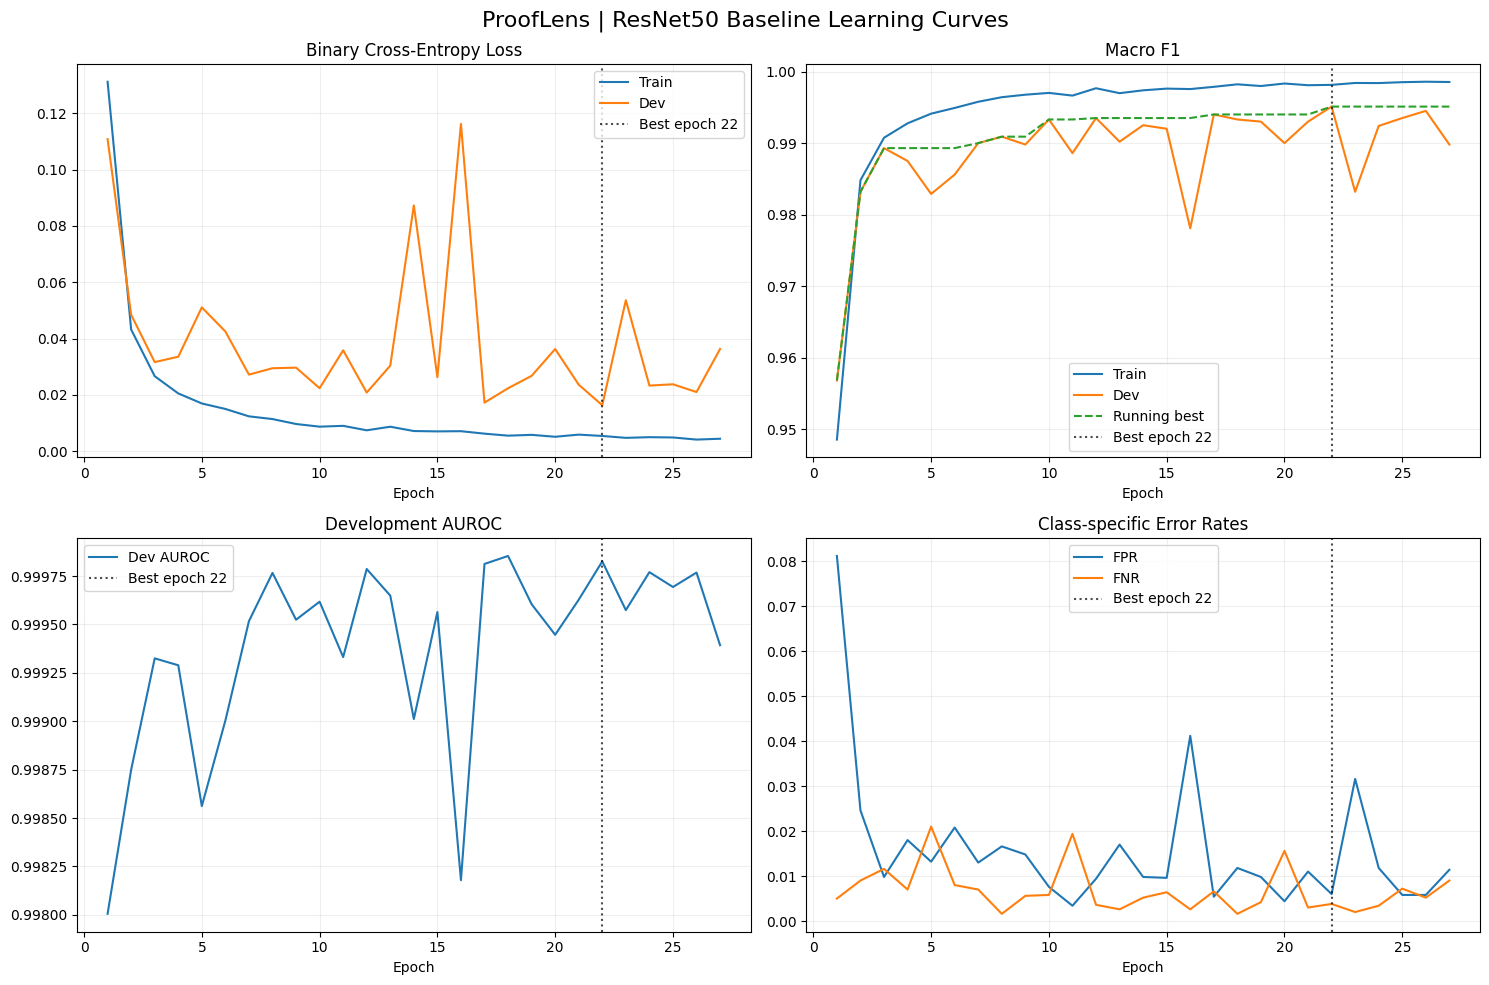

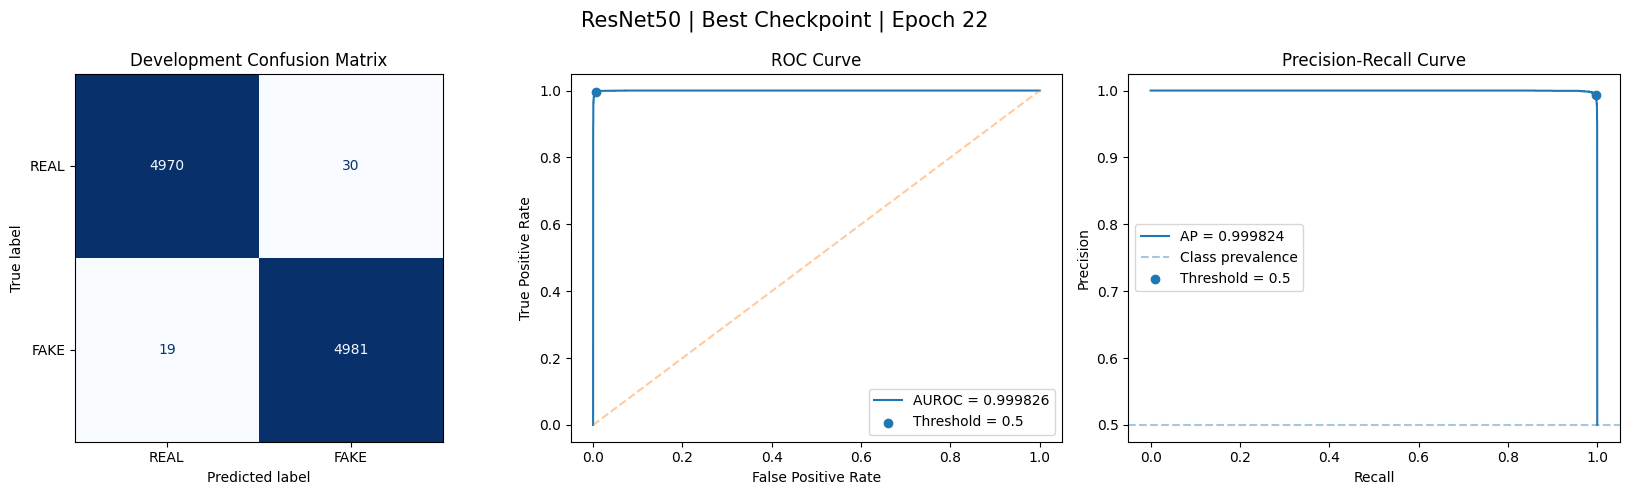

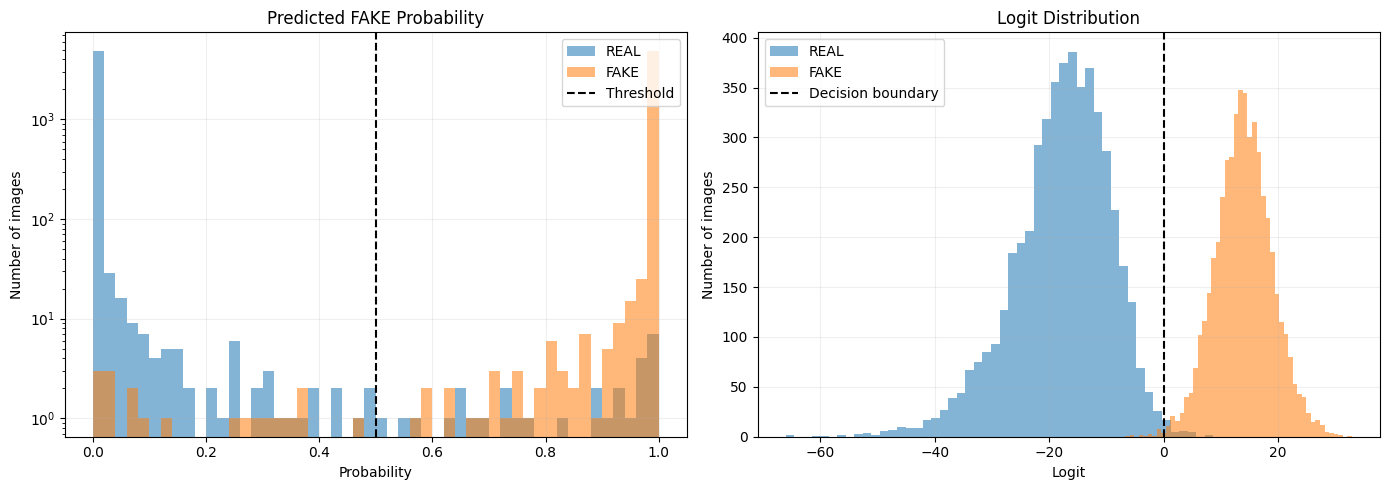


[7/7] Saving evaluation report...

PROOFLENS — RESNET50 BASELINE EVALUATION COMPLETE

EXPERIMENT
Architecture           : resnet50
Experiment ID          : baseline
Dataset release        : genimage-120k-v1
Seed                   : 42
Completed epochs       : 27
Selected epoch         : 22

DEVELOPMENT PERFORMANCE
Evaluated images       : 10,000
Correct predictions    : 9,951
Incorrect predictions  : 49
Accuracy               : 99.5100%
Macro F1               : 0.995100
AUROC                  : 0.999826
Average Precision      : 0.999824
FAKE Precision         : 99.4013%
FAKE Recall            : 99.6200%
FPR                    : 0.6000%
FNR                    : 0.3800%

CONFUSION MATRIX
True Negative          : 4,970
False Positive         : 30
False Negative         : 19
True Positive          : 4,981

ARTIFACTS
Prediction parquet     : SAVED & VERIFIED
Generator group metrics: SAVED & VERIFIED
Metric reproduction    : SAVED & VERIFIED
Evaluation report      : SAVED & VERIFIED
Researc

In [6]:

# ============================================================
# CELL 5 — BASELINE EVALUATION & ARTIFACT EXPORT
# ProofLens | ResNet50 Baseline Research
# ============================================================

import gc
import json
import math
import time
import tempfile

from datetime import datetime, timezone

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    precision_recall_curve,
)

from IPython.display import display

started_5 = time.perf_counter()

BASELINE_EVALUATION_COMPLETED = False

assert ENVIRONMENT_READY
assert DATASET_READY
assert MODEL_READY
assert TRAINING_COMPLETED

# ------------------------------------------------------------
# 1. Verify and load the selected checkpoint
# ------------------------------------------------------------

print("[1/7] Verifying best model checkpoint...")

summary = json.loads(
    TRAINING_SUMMARY_PATH.read_text(encoding="utf-8")
)

assert summary["execution"]["training_completed"]

assert summary["configuration"][
    "config_fingerprint"
] == CONFIG_FINGERPRINT

assert summary["dataset"][
    "manifest_sha256"
] == MANIFEST_SHA256

assert summary["seed"] == SEED

assert summary["research_controls"][
    "test_sets_evaluated"
] is False

assert BEST_MODEL_PATH.is_file()

best_model_sha256 = sha256_file(
    BEST_MODEL_PATH
)

assert best_model_sha256 == summary[
    "artifacts"
]["best_model_sha256"]

# Load only the trusted checkpoint produced by this run.
best_checkpoint = torch.load(
    BEST_MODEL_PATH,
    map_location="cpu",
    weights_only=False,
)

assert best_checkpoint["identity"] == (
    CHECKPOINT_IDENTITY
)

SELECTED_EPOCH = int(
    best_checkpoint["epoch"]
)

assert SELECTED_EPOCH == summary[
    "best_epoch_metrics"
]["epoch"]

assert best_checkpoint[
    "decision_threshold"
] == DECISION_THRESHOLD

assert math.isclose(
    best_checkpoint["dev_macro_f1"],
    summary["best_epoch_metrics"]["dev_macro_f1"],
    abs_tol=1e-12,
)

model.load_state_dict(
    best_checkpoint["model_state_dict"],
    strict=True,
)

model.eval()

del best_checkpoint

optimizer.zero_grad(set_to_none=True)

gc.collect()
torch.cuda.empty_cache()

print(f"Selected epoch: {SELECTED_EPOCH}")
print(f"Checkpoint SHA256: {best_model_sha256[:16]}...")
print("Checkpoint identity: PASS")
print("Checkpoint checksum: PASS")
print("Model mode: EVAL")

# ------------------------------------------------------------
# 2. Reproduce development predictions
# ------------------------------------------------------------

print("\n[2/7] Running development inference...")

dev_metrics, dev_predictions = validate_one_epoch(
    epoch=SELECTED_EPOCH,
    collect_predictions=True,
)

validate_epoch_metrics(
    dev_metrics,
    expected_samples=len(dev_dataset),
)

assert dev_metrics["optimizer_steps"] == 0

assert len(dev_predictions) == len(dev_manifest)
assert len(dev_predictions) == 10000

assert dev_predictions["image_id"].is_unique

assert dev_predictions[
    "release_split"
].eq("dev").all()

assert dev_predictions["label"].value_counts().to_dict() == {
    0: 5000,
    1: 5000,
}

assert dev_predictions[
    "image_id"
].astype(str).tolist() == dev_manifest[
    "image_id"
].astype(str).tolist()

assert np.array_equal(
    dev_predictions["label"].to_numpy(),
    dev_manifest["label"].to_numpy(dtype=np.int64),
)

assert dev_predictions[
    "source_generator_group"
].astype(str).tolist() == dev_manifest[
    "source_generator_group"
].astype(str).tolist()

labels = dev_predictions[
    "label"
].to_numpy(dtype=np.int64)

probabilities = dev_predictions[
    "probability_fake"
].to_numpy(dtype=np.float64)

logits = dev_predictions[
    "logit"
].to_numpy(dtype=np.float64)

predictions = dev_predictions[
    "predicted_label"
].to_numpy(dtype=np.int64)

assert np.isfinite(logits).all()
assert np.isfinite(probabilities).all()

assert np.array_equal(
    predictions,
    (probabilities >= DECISION_THRESHOLD).astype(np.int64),
)

# Additional fields for downstream error analysis.
dev_predictions["checkpoint_epoch"] = SELECTED_EPOCH
dev_predictions["is_correct"] = labels == predictions

dev_predictions["error_type"] = np.select(
    [
        (labels == 0) & (predictions == 0),
        (labels == 0) & (predictions == 1),
        (labels == 1) & (predictions == 0),
        (labels == 1) & (predictions == 1),
    ],
    ["TN", "FP", "FN", "TP"],
    default="INVALID",
)

assert not dev_predictions[
    "error_type"
].eq("INVALID").any()

dev_predictions["prediction_confidence"] = np.maximum(
    probabilities,
    1.0 - probabilities,
)

print("Development predictions: PASS")
print("Image ID alignment: PASS")
print("Label alignment: PASS")
print("Generator metadata alignment: PASS")
print("Test images evaluated: NO")

# ------------------------------------------------------------
# 3. Validate metric reproduction
# ------------------------------------------------------------

print("\n[3/7] Validating reproduced metrics...")

history_df = pd.DataFrame(
    TRAIN_HISTORY
).sort_values("epoch").reset_index(drop=True)

assert len(history_df) == summary[
    "execution"
]["completed_epochs"]

recorded = history_df.loc[
    history_df["epoch"].eq(SELECTED_EPOCH)
].iloc[0]

assert int(
    history_df.loc[
        history_df["dev_macro_f1"].idxmax(),
        "epoch",
    ]
) == SELECTED_EPOCH

comparison_records = []

comparison_metrics = [
    "loss",
    "accuracy",
    "macro_f1",
    "precision_fake",
    "recall_fake",
    "f1_fake",
    "balanced_accuracy",
    "auroc",
    "average_precision",
    "specificity",
    "false_positive_rate",
    "false_negative_rate",
]

for metric in comparison_metrics:

    expected = float(recorded[f"dev_{metric}"])
    observed = float(dev_metrics[metric])

    # Small floating-point tolerance for GPU inference.
    if metric == "loss":

        passed = math.isclose(
            expected,
            observed,
            rel_tol=1e-3,
            abs_tol=1e-5,
        )

    elif metric in {"auroc", "average_precision"}:

        passed = math.isclose(
            expected,
            observed,
            rel_tol=0,
            abs_tol=1e-6,
        )

    else:

        passed = math.isclose(
            expected,
            observed,
            rel_tol=0,
            abs_tol=1e-10,
        )

    comparison_records.append({
        "metric": metric,
        "recorded": expected,
        "reproduced": observed,
        "absolute_difference": abs(expected - observed),
        "passed": bool(passed),
    })

comparison_df = pd.DataFrame(
    comparison_records
)

display(comparison_df)

assert comparison_df["passed"].all(), (
    "Metric reproduction mismatch. "
    "Investigate before publishing evaluation artifacts."
)

cm = confusion_matrix(
    labels,
    predictions,
    labels=[0, 1],
)

tn, fp, fn, tp = map(
    int,
    cm.ravel(),
)

for name, value in zip(
    ["tn", "fp", "fn", "tp"],
    [tn, fp, fn, tp],
):

    assert value == int(recorded[f"dev_{name}"])
    assert value == dev_metrics[name]

assert tn + fp + fn + tp == 10000

print("Recorded metrics reproduction: PASS")
print("Confusion matrix reproduction: PASS")

# ------------------------------------------------------------
# 4. Export per-image development predictions
# ------------------------------------------------------------

print("\n[4/7] Exporting development predictions...")

DEV_GROUP_METRICS_PATH = (
    RUN_DIR / "dev_group_metrics.csv"
)

METRIC_REPRODUCTION_PATH = (
    RUN_DIR / "metric_reproduction.csv"
)

FIGURES_DIR = RUN_DIR / "figures"

FIGURES_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

with tempfile.TemporaryDirectory(
    dir=str(WORK_DIR)
) as temporary_directory:

    local_predictions = (
        Path(temporary_directory)
        / "dev_predictions.parquet"
    )

    dev_predictions.to_parquet(
        local_predictions,
        index=False,
    )

    predictions_sha256 = copy_file_verified(
        local_predictions,
        PREDICTIONS_PATH,
    )

restored_predictions = pd.read_parquet(
    PREDICTIONS_PATH
)

pd.testing.assert_frame_equal(
    dev_predictions.reset_index(drop=True),
    restored_predictions.reset_index(drop=True),
    check_exact=True,
)

del restored_predictions

print(f"Exported predictions: {len(dev_predictions):,}")
print(f"Prediction SHA256: {predictions_sha256[:16]}...")
print("Parquet read-back validation: PASS")

# ------------------------------------------------------------
# 5. Source generator group analysis
# ------------------------------------------------------------

print("\n[5/7] Analyzing source generator groups...")

assert dev_predictions[
    "source_generator_group"
].notna().all()

group_records = []

for group_name, group in dev_predictions.groupby(
    "source_generator_group",
    sort=True,
):

    y = group["label"].to_numpy(dtype=np.int64)

    p = group[
        "probability_fake"
    ].to_numpy(dtype=np.float64)

    z = group["logit"].to_numpy(dtype=np.float64)

    # Numerically stable per-sample binary cross-entropy.
    group_loss = float(
        np.mean(
            np.logaddexp(0.0, z) - y * z
        )
    )

    group_pred = group[
        "predicted_label"
    ].to_numpy(dtype=np.int64)

    gtn, gfp, gfn, gtp = map(
        int,
        confusion_matrix(
            y,
            group_pred,
            labels=[0, 1],
        ).ravel(),
    )

    group_record = {
        "source_generator_group": str(group_name),
        "num_samples": int(len(group)),
        "real_samples": int((y == 0).sum()),
        "fake_samples": int((y == 1).sum()),
        "loss": group_loss,
        "accuracy": float((y == group_pred).mean()),
        "tn": gtn,
        "fp": gfp,
        "fn": gfn,
        "tp": gtp,
    }

    # Ranking and two-class metrics require both classes.
    if set(np.unique(y)) == {0, 1}:

        group_metrics = calculate_metrics(
            labels=y,
            probabilities=p,
            mean_loss=group_loss,
            threshold=DECISION_THRESHOLD,
        )

        group_record.update({
            name: group_metrics[name]
            for name in [
                "macro_f1",
                "auroc",
                "average_precision",
                "precision_fake",
                "recall_fake",
                "false_positive_rate",
                "false_negative_rate",
            ]
        })

    else:

        group_record.update({
            "macro_f1": None,
            "auroc": None,
            "average_precision": None,
            "precision_fake": (
                gtp / (gtp + gfp)
                if gtp + gfp else None
            ),
            "recall_fake": (
                gtp / (gtp + gfn)
                if gtp + gfn else None
            ),
            "false_positive_rate": (
                gfp / (gfp + gtn)
                if gfp + gtn else None
            ),
            "false_negative_rate": (
                gfn / (gfn + gtp)
                if gfn + gtp else None
            ),
        })

    group_record["errors"] = gfp + gfn

    group_records.append(group_record)

group_df = pd.DataFrame(
    group_records
)

assert group_df["num_samples"].sum() == 10000

assert group_df["real_samples"].sum() == 5000
assert group_df["fake_samples"].sum() == 5000

assert group_df["errors"].sum() == fp + fn

for name, value in zip(
    ["tn", "fp", "fn", "tp"],
    [tn, fp, fn, tp],
):

    assert group_df[name].sum() == value

# Validate and persist CSV artifacts.
def export_csv_verified(frame, destination):

    with tempfile.TemporaryDirectory(
        dir=str(WORK_DIR)
    ) as temporary_directory:

        local_path = (
            Path(temporary_directory)
            / destination.name
        )

        frame.to_csv(
            local_path,
            index=False,
        )

        digest = copy_file_verified(
            local_path,
            destination,
        )

    readback = pd.read_csv(destination)

    assert len(readback) == len(frame)
    assert list(readback.columns) == list(frame.columns)

    return digest


group_metrics_sha256 = export_csv_verified(
    group_df,
    DEV_GROUP_METRICS_PATH,
)

comparison_sha256 = export_csv_verified(
    comparison_df,
    METRIC_REPRODUCTION_PATH,
)

display(
    group_df.round(6)
)

print("\nMisclassification summary:")

display(
    dev_predictions.loc[
        ~dev_predictions["is_correct"]
    ].groupby(
        ["source_generator_group", "error_type"]
    ).size().rename(
        "num_errors"
    ).reset_index()
)

# ------------------------------------------------------------
# 6. Generate research visualizations
# ------------------------------------------------------------

print("\n[6/7] Generating research visualizations...")

figure_artifacts = {}


def export_figure(fig, filename):

    destination = FIGURES_DIR / filename

    with tempfile.TemporaryDirectory(
        dir=str(WORK_DIR)
    ) as temporary_directory:

        local_path = (
            Path(temporary_directory)
            / filename
        )

        fig.savefig(
            local_path,
            dpi=180,
            bbox_inches="tight",
            facecolor="white",
        )

        digest = copy_file_verified(
            local_path,
            destination,
        )

    figure_artifacts[filename] = {
        "path": str(destination),
        "sha256": digest,
    }

    plt.show()
    plt.close(fig)


# Figure 1: Complete learning curves.
fig, axes = plt.subplots(
    2, 2,
    figsize=(15, 10),
)

epochs = history_df["epoch"]

axes[0, 0].plot(
    epochs,
    history_df["train_loss"],
    label="Train",
)

axes[0, 0].plot(
    epochs,
    history_df["dev_loss"],
    label="Dev",
)

axes[0, 0].set_title(
    "Binary Cross-Entropy Loss"
)

axes[0, 1].plot(
    epochs,
    history_df["train_macro_f1"],
    label="Train",
)

axes[0, 1].plot(
    epochs,
    history_df["dev_macro_f1"],
    label="Dev",
)

axes[0, 1].plot(
    epochs,
    history_df["dev_macro_f1"].cummax(),
    linestyle="--",
    label="Running best",
)

axes[0, 1].set_title("Macro F1")

axes[1, 0].plot(
    epochs,
    history_df["dev_auroc"],
    label="Dev AUROC",
)

axes[1, 0].set_title("Development AUROC")

axes[1, 1].plot(
    epochs,
    history_df["dev_false_positive_rate"],
    label="FPR",
)

axes[1, 1].plot(
    epochs,
    history_df["dev_false_negative_rate"],
    label="FNR",
)

axes[1, 1].set_title("Class-specific Error Rates")

for ax in axes.ravel():

    ax.axvline(
        SELECTED_EPOCH,
        linestyle=":",
        color="black",
        alpha=0.7,
        label=f"Best epoch {SELECTED_EPOCH}",
    )

    ax.set_xlabel("Epoch")
    ax.grid(alpha=0.2)
    ax.legend()

fig.suptitle(
    "ProofLens | ResNet50 Baseline Learning Curves",
    fontsize=16,
)

fig.tight_layout()

export_figure(
    fig,
    "learning_curves.png",
)

# Figure 2: Best checkpoint evaluation.
fpr_curve, tpr_curve, _ = roc_curve(
    labels,
    probabilities,
)

pr_precision, pr_recall, _ = precision_recall_curve(
    labels,
    probabilities,
)

fig, axes = plt.subplots(
    1, 3,
    figsize=(17, 5),
)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["REAL", "FAKE"],
).plot(
    ax=axes[0],
    colorbar=False,
    cmap="Blues",
    values_format="d",
)

axes[0].set_title("Development Confusion Matrix")

axes[1].plot(
    fpr_curve,
    tpr_curve,
    label=f"AUROC = {dev_metrics['auroc']:.6f}",
)

axes[1].plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    alpha=0.4,
)

axes[1].scatter(
    dev_metrics["false_positive_rate"],
    dev_metrics["recall_fake"],
    label="Threshold = 0.5",
)

axes[1].set_xlabel("False Positive Rate")
axes[1].set_ylabel("True Positive Rate")
axes[1].set_title("ROC Curve")
axes[1].legend()

axes[2].plot(
    pr_recall,
    pr_precision,
    label=(
        f"AP = "
        f"{dev_metrics['average_precision']:.6f}"
    ),
)

axes[2].axhline(
    labels.mean(),
    linestyle="--",
    alpha=0.4,
    label="Class prevalence",
)

axes[2].scatter(
    dev_metrics["recall_fake"],
    dev_metrics["precision_fake"],
    label="Threshold = 0.5",
)

axes[2].set_xlabel("Recall")
axes[2].set_ylabel("Precision")
axes[2].set_title("Precision-Recall Curve")
axes[2].legend()

fig.suptitle(
    f"ResNet50 | Best Checkpoint | Epoch {SELECTED_EPOCH}",
    fontsize=15,
)

fig.tight_layout()

export_figure(
    fig,
    "development_evaluation.png",
)

# Figure 3: Class-conditional prediction scores.
fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 5),
)

for class_id, class_name in [
    (0, "REAL"),
    (1, "FAKE"),
]:

    mask = labels == class_id

    axes[0].hist(
        probabilities[mask],
        bins=np.linspace(0, 1, 51),
        alpha=0.55,
        label=class_name,
    )

    axes[1].hist(
        logits[mask],
        bins=50,
        alpha=0.55,
        label=class_name,
    )

axes[0].axvline(
    DECISION_THRESHOLD,
    linestyle="--",
    color="black",
    label="Threshold",
)

axes[1].axvline(
    0,
    linestyle="--",
    color="black",
    label="Decision boundary",
)

axes[0].set_title("Predicted FAKE Probability")
axes[0].set_xlabel("Probability")
axes[0].set_yscale("log")

axes[1].set_title("Logit Distribution")
axes[1].set_xlabel("Logit")

for ax in axes:

    ax.set_ylabel("Number of images")
    ax.legend()
    ax.grid(alpha=0.2)

fig.tight_layout()

export_figure(
    fig,
    "prediction_distributions.png",
)

# ------------------------------------------------------------
# 7. Save and validate final evaluation artifacts
# ------------------------------------------------------------

print("\n[7/7] Saving evaluation report...")

evaluation_report = {
    "project": PROJECT_NAME,
    "model_name": MODEL_NAME,
    "experiment_id": EXPERIMENT_ID,
    "seed": SEED,
    "dataset_release": RELEASE_ID,
    "sampling_plan_id": EXPECTED_PLAN_ID,
    "manifest_sha256": MANIFEST_SHA256,
    "dataset_quality_status": QUALITY_STATUS,
    "config_fingerprint": CONFIG_FINGERPRINT,
    "repository_commit": ACTUAL_COMMIT,

    "checkpoint": {
        "selected_epoch": SELECTED_EPOCH,
        "selection_metric": "dev_macro_f1",
        "selection_split": "dev",
        "path": str(BEST_MODEL_PATH),
        "sha256": best_model_sha256,
    },

    "evaluation": {
        "split": "dev",
        "num_images": len(dev_predictions),
        "decision_threshold": DECISION_THRESHOLD,
        "metrics": dev_metrics,
        "metric_reproduction_passed": True,
        "correct_predictions": int(tn + tp),
        "incorrect_predictions": int(fp + fn),
        "confusion_matrix": cm.tolist(),
        "confusion_matrix_labels": ["REAL", "FAKE"],
        "generator_groups": len(group_df),
        "independent_test_performance": False,
    },

    "training": {
        "completed_epochs": len(history_df),
        "stop_reason": summary["execution"]["stop_reason"],
    },

    "artifacts": {
        "predictions": {
            "path": str(PREDICTIONS_PATH),
            "sha256": predictions_sha256,
        },
        "generator_group_metrics": {
            "path": str(DEV_GROUP_METRICS_PATH),
            "sha256": group_metrics_sha256,
        },
        "metric_reproduction": {
            "path": str(METRIC_REPRODUCTION_PATH),
            "sha256": comparison_sha256,
        },
        "figures": figure_artifacts,
    },

    "research_controls": {
        "training_performed": False,
        "threshold_optimized": False,
        "jpeg_augmentation": False,
        "resolution_augmentation": False,
        "test_images_loaded": False,
        "test_sets_evaluated": False,
        "dataset_modified": False,
        "development_results_only": True,
    },

    "evaluation_duration_seconds": round(
        time.perf_counter() - started_5,
        3,
    ),

    "evaluated_at_utc": datetime.now(
        timezone.utc
    ).isoformat(),
}

write_json_verified(
    METRICS_PATH,
    evaluation_report,
)

# Confirm the selected checkpoint was not modified.
assert sha256_file(
    BEST_MODEL_PATH
) == best_model_sha256

assert sha256_file(
    PREDICTIONS_PATH
) == predictions_sha256

assert sha256_file(
    DEV_GROUP_METRICS_PATH
) == group_metrics_sha256

assert sha256_file(
    METRIC_REPRODUCTION_PATH
) == comparison_sha256

for artifact in figure_artifacts.values():

    assert sha256_file(
        Path(artifact["path"])
    ) == artifact["sha256"]

BASELINE_EVALUATION_COMPLETED = True

# ------------------------------------------------------------
# 8. Final baseline evaluation summary
# ------------------------------------------------------------

print("\n" + "=" * 68)
print("PROOFLENS — RESNET50 BASELINE EVALUATION COMPLETE")
print("=" * 68)

print("\nEXPERIMENT")
print(f"Architecture           : {MODEL_NAME}")
print(f"Experiment ID          : {EXPERIMENT_ID}")
print(f"Dataset release        : {RELEASE_ID}")
print(f"Seed                   : {SEED}")
print(f"Completed epochs       : {len(history_df)}")
print(f"Selected epoch         : {SELECTED_EPOCH}")

print("\nDEVELOPMENT PERFORMANCE")
print(f"Evaluated images       : {len(dev_predictions):,}")
print(f"Correct predictions    : {tn + tp:,}")
print(f"Incorrect predictions  : {fp + fn:,}")
print(f"Accuracy               : {dev_metrics['accuracy']:.4%}")
print(f"Macro F1               : {dev_metrics['macro_f1']:.6f}")
print(f"AUROC                  : {dev_metrics['auroc']:.6f}")
print(f"Average Precision      : {dev_metrics['average_precision']:.6f}")
print(f"FAKE Precision         : {dev_metrics['precision_fake']:.4%}")
print(f"FAKE Recall            : {dev_metrics['recall_fake']:.4%}")
print(f"FPR                    : {dev_metrics['false_positive_rate']:.4%}")
print(f"FNR                    : {dev_metrics['false_negative_rate']:.4%}")

print("\nCONFUSION MATRIX")
print(f"True Negative          : {tn:,}")
print(f"False Positive         : {fp:,}")
print(f"False Negative         : {fn:,}")
print(f"True Positive          : {tp:,}")

print("\nARTIFACTS")
print("Prediction parquet     : SAVED & VERIFIED")
print("Generator group metrics: SAVED & VERIFIED")
print("Metric reproduction    : SAVED & VERIFIED")
print("Evaluation report      : SAVED & VERIFIED")
print(f"Research figures       : {len(figure_artifacts)}")
print("Best checkpoint        : UNMODIFIED")

print("\nVALIDATION")
print("Checkpoint identity    : PASS")
print("Checkpoint checksum    : PASS")
print("Metric reproduction    : PASS")
print("Image ID alignment     : PASS")
print("Confusion matrix       : PASS")
print("Artifact checksums     : PASS")

print("\nRESEARCH CONTROLS")
print("Training performed     : NO")
print("Threshold optimized    : NO")
print("Test sets evaluated    : NO")
print("Dataset modified       : NO")

print("\nFINAL STATUS")
print("Baseline training      : COMPLETE")
print("Baseline Dev evaluation: COMPLETE")
print("Seed 42 artifacts      : COMPLETE")
print("Multi-seed evaluation  : PENDING")
print("Independent test       : LOCKED")

print(
    f"\nEvaluation duration    : "
    f"{time.perf_counter() - started_5:.2f}s"
)

print(f"Artifact directory     : {RUN_DIR}")

print("=" * 68)

print(
    "\nCELL 5 COMPLETE — "
    "RESNET50 SEED 42 BASELINE FINISHED."
)
